In [6]:
import shutil
import pandas as pd
import random

import copy
import numpy as np # Import numpy for checking finite values
import matplotlib.pyplot as plt # Import matplotlib for potential debugging

import os
import math # Import math for ceil
from sklearn.manifold import TSNE # Import TSNE to check default perplexity

import os
import glob
import json
import numpy as np
import tensorflow as tf
import sys
from itertools import zip_longest
import optuna

In [7]:
import sys
fixed_path = 'C:\\Users\\Enrico Didoli\\0.Master_Thesis\\'
#fixed_path = 'C:\\Users\\admin\\0.Master_Thesis\\'

if fixed_path not in sys.path:
    sys.path.append(fixed_path)

old_cellcnn_path = f'{fixed_path}CellCNN/Old_CellCNN/'
if old_cellcnn_path not in sys.path:
    sys.path.append(old_cellcnn_path)

cellcnn_path = f'{fixed_path}CellCNN/'
if cellcnn_path not in sys.path:
    sys.path.append(cellcnn_path)
    
general_functions_path = f'{fixed_path}General_Functions/'
if general_functions_path not in sys.path:
    sys.path.append(general_functions_path)

save_path = f'{fixed_path}CellCNN/results/'
if save_path not in sys.path:
    sys.path.append(save_path)

In [8]:
decache_files = ['timepoints_elaboration', 'results_elaboration', 'new_datasets_generation', 'run_models',
                 'old_cellCnn.model', 'old_cellCnn.utils', 'old_cellCnn.downsample', 'old_cellCnn.model_grid',
                'All_fixed_functions']

# Rimuovi il modulo specifico dalla cache
from timepoints_elaboration import remove_from_cache
remove_from_cache(decache_files)


# import downloaded modules
from old_cellCnn.model import CellCnn

import old_cellCnn.utils as utils
import old_cellCnn.downsample as downsample

from timepoints_elaboration import load_data, donation_extraction, dataset_elaboration
from timepoints_elaboration import donor_division, patient_code_extraction, remove_from_cache

from results_elaboration import extract_hyper, phenotype_prediction, default_serializer, show_hyperparameters
from results_elaboration import elaborate_predictions, show_hyper

from run_models import trials_train_CellCNN, trials_test_CellCNN, trials_train_CellCNN_old, trials_test_CellCNN_old

from new_datasets_generation import splitting_and_dataset_elaboration


timepoints_elaboration rimosso dalla cache
results_elaboration rimosso dalla cache
new_datasets_generation rimosso dalla cache
run_models rimosso dalla cache
old_cellCnn.model rimosso dalla cache
old_cellCnn.utils rimosso dalla cache
old_cellCnn.downsample rimosso dalla cache
old_cellCnn.model_grid non trovato nella cache
All_fixed_functions non trovato nella cache


In [9]:
def remove_labels(new_test_datasets):
    new_no_label_test_datasets = []
    for dataset in new_test_datasets:
        if 'IsBlast' in dataset.columns:
            dataset = dataset.drop(columns = ['IsBlast'])
        
        new_no_label_test_datasets.append(dataset)
    print(len(new_no_label_test_datasets))
    return new_no_label_test_datasets

def show_blast_distribution_perc(ALL_DATASETS, return_perc = False):
    tot_perc_list = []
    for i, dataset in enumerate(ALL_DATASETS):
        blast_n = (dataset['IsBlast'] == 1).sum()
        tot_perc_list.append(round((blast_n/len(dataset))*100, 2))
    
    positions = range(1, len(tot_perc_list) + 1)
    
    fig, ax1 = plt.subplots(figsize = [len(positions)/2,4])
    ax1.bar(list(range(1, len(tot_perc_list) + 1)), [max(tot_perc_list)]*len(tot_perc_list), alpha = 0.5)
    ax1.bar(list(range(1, len(tot_perc_list) + 1)), tot_perc_list)
    ax1.set_xticks(positions)
    
    ax2 = ax1.twiny()
    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticks(ax1.get_xticks()) # Positions [1, 2, 3, 4]
    
    ax2.set_xticklabels(tot_perc_list, size = 'x-small')
    plt.show()

    if return_perc:
        return tot_perc_list

def show_blast_distribution_num(ALL_DATASETS, return_num = False):
    tot_perc_list = []
    for i, dataset in enumerate(ALL_DATASETS):
        blast_n = (dataset['IsBlast'] == 1).sum()
        tot_num_list.append(blast_n)
    
    positions = range(1, len(tot_num_list) + 1)
    
    fig, ax1 = plt.subplots(figsize = [len(positions)/2,4])
    ax1.bar(list(range(1, len(tot_num_list) + 1)), [max(tot_num_list)]*len(tot_num_list), alpha = 0.5)
    ax1.bar(list(range(1, len(tot_num_list) + 1)), tot_num_list)
    ax1.set_xticks(positions)
    
    ax2 = ax1.twiny()
    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticks(ax1.get_xticks()) # Positions [1, 2, 3, 4]
    
    ax2.set_xticklabels(tot_num_list, size = 'x-small')
    plt.show()

    if return_num:
        return tot_num_list

def grid_or_rand_model(grid):
    if grid:
        remove_from_cache(['old_cellCnn.model_grid'])
        from old_cellCnn.model_grid import CellCnn
    else:
        remove_from_cache(['old_cellCnn.model'])
        from old_cellCnn.model import CellCnn
    return CellCnn

def train_val_finalizing(train_datasets, val_datasets, grid, labels):
    """
    Renames rain and valdation sets.
    Removes Labels in case of grid search or no labels required.
    """
    if grid:
        train = remove_labels(train_datasets)
        val = remove_labels(val_datasets)
        print(f'_abels from Train and Validations Sets have been REMOVED.\nGrid Search Ready!')
    else:
        if not labels: # if random search but we don't want use labels
            train = remove_labels(train_datasets)
            val = remove_labels(val_datasets)
            print(f'labels from Train and Validations Sets have been REMOVED.\nRandom Search Ready!')
            
        else:
            train = train_datasets
            val = val_datasets
            print(f'Labels from Train and Validations Sets have been PRESERVED.\nRandom Search Ready!')
            
    return train, val

def prepare_results_to_save(results_list, par_list = ['config', 'model_sorted_idx']):
    """
    Construct a list of dictionaries to store predictions
    Each dictionary contains the configuration and the sorted runs for each trial
    """
    tot_trials_res = []

    for res in results_list:
        needed_results = {}
        for key, value in res.items():
            if key in par_list:
                needed_results[key] = value
                
        tot_trials_res.append(needed_results)
    return tot_trials_res

def retrieve_labels(datasets_extracted, remove = False, concat = False, flat = False):
    
    per_donor_original_datasets = []
    per_donor_original_y = []

    for donor in datasets_extracted:
        donor_datasets = []
        donor_ys = []
        for dataset in donor:
            if (dataset['IsBlast'] == 1).sum() > 0:
                donor_ys.append(1)
            else:
                donor_ys.append(0)
                
            if remove:
                dataset = dataset.drop(columns = ['IsBlast'])

            donor_datasets.append(dataset)

        if concat:
            per_donor_original_datasets += donor_datasets
            per_donor_original_y += donor_ys
        else:
            per_donor_original_datasets.append(donor_datasets)
            per_donor_original_y.append(donor_ys)


    if flat:
        per_donor_original_datasets = flatten(per_donor_original_datasets)
        per_donor_original_y = flatten(per_donor_original_y)
        
    return per_donor_original_datasets, per_donor_original_y 

def subset_sampling(dataset, ncells, nsubsets, seed):
    resampled_datasets = []
    resampled_y = []
    blast_perc = []
    
    for i in range(nsubsets):
        seed += 10
        #print(f'seed:{seed}')
        resampled_cells = dataset.sample(ncells, replace = True, random_state = seed).reset_index(drop=True) # sample cells
            
        if (resampled_cells['IsBlast'] == 1).sum() > 0: #check label
                resampled_y.append(1)
                blast_perc.append((resampled_cells[resampled_cells['IsBlast'] == 1]).sum()/len(resampled_cells))
        else:
                resampled_y .append(0)
                blast_perc.append(0)
        resampled_cells = resampled_cells.drop(columns = ['IsBlast']) #remove isblast column

        resampled_datasets.append(resampled_cells) 
    return    resampled_datasets,  resampled_y , blast_perc, seed


def get_timepoints_predictions(total_pred_lists, per_donor_original_test_y, threshold):
    total_labels = []
    
    for patient in total_pred_lists:
        patient_timepoints_labels = []
        
        for timepoint in patient:
            timepoint_f1_scores = []
            blast_labelled_timepoint_scores = []
            
            true_y = timepoint.iloc[-1]
            
            for trial in range(len(timepoint.iloc[:-1])): # from each timepoint multiple samples has been generated. each sample has been predicted 10 times using the same 'best' model but using a different seed each time
                sub = timepoint.iloc[trial]               # each sub is a pediction of the 20 samples of a single timepoint
                blast_labelled_perc = sub.sum()/len(true_y)
                blast_labelled_timepoint_scores.append(blast_labelled_perc) #percentage of timepoints labelled as with blast cells
     
            mean_timepoint_blast_score = np.mean(blast_labelled_timepoint_scores) # mean percentage of timepoints labelled as with blast cells
            
            if mean_timepoint_blast_score >= threshold*0.01:
                patient_timepoints_labels.append(1)
            else:
                patient_timepoints_labels.append(0)
                
        total_labels.append(patient_timepoints_labels)
    return total_labels


def get_trial_pred_per_timepoint(total_pred_lists, per_donor_original_test_y):
    plot_data = []
    boxplot_data = []
    total_timepoint_prediction_per_trial = []
    
    for patient, patient_ys in zip(total_pred_lists, per_donor_original_test_y):
        timepoint_prediction_per_trial = []
        
        for timepoint, true_timepoint_y in zip(patient, patient_ys):
            label_str = "Positive" if true_timepoint_y == 1 else "Negative"
            
            trial_level_label_prediction = []
            true_y = timepoint.iloc[-1]
            timepoint_boxplot_data = []
            
            for trial in range(len(timepoint.iloc[:-1])): # from each timepoint multiple samples has been generated. each sample has been predicted 10 times using the same 'best' model but using a different seed each time
                sub = timepoint.iloc[trial]               # each sub is a pediction of the 20 samples of a single timepoint
                
                trial_perc = sub.sum()/len(true_y)
                #trial_perc = sub.sum()/min(1, true_y.sum())
            
                #trial_level_label_prediction.append((blast_labelled_perc >= threshold*0.01).astype(int))
                plot_data.append({
                "True_Label": label_str,
                "Timepoint_Score": trial_perc
                })
                
                timepoint_boxplot_data.append(trial_perc)
                
            boxplot_data.append({
                "True_Label": true_timepoint_y,
                "Timepoint_trials_scores": timepoint_boxplot_data
                })
                
    return plot_data, boxplot_data

def compute_timepoint_best_f1(timepoint_preds):
        """we are taking the best f1 score. because we are not tuning the model. we are just trying to predict the label of the timepoint"""
        timepoint_score = []
        
        resampled_true_y = timepoint_preds.iloc[-1] # get labels of resampled subsets
        #print(timepoint_preds.iloc[:-1]) #labels

        # initialize variables
        best_f1 = -1
        counter = 0
        
        for h in range(len(timepoint_preds) - 1):
            sub = timepoint_preds.iloc[h] # extrsct trial pediction
            
            f1 = f1_score(resampled_true_y, sub, pos_label = 1) # compute the f1_score
            if f1 > best_f1:
                best_f1_idx = counter
            counter += 1
            
        print(best_f1_idx)   
        best_sub = timepoint_preds.iloc[best_f1_idx]
        #print(len(true_y))
        blast_score = best_sub.sum() 
        print('')
        #print(best_sub)
        #print(f'blast_score: {blast_score}\n')
        timepoint_score = blast_score.sum()/len(resampled_true_y)
        return (timepoint_score, list(resampled_true_y))


def find_threshold(total_scores, per_donor_original_val_y):
    best_f1 = -1
    best_thr = -1
    tot_mean_f1_scores = []
    threshold_predictions = []
    for threshold in list(range(1,101)):
        f1_scores = []
        patient_predictions = []
        for patient_score, patient_y in zip(total_scores, per_donor_original_val_y):
            scores = []
            
            for timep in patient_score:
                # get mean columns predicted probabilities 
                scores.append(timep[0]) 
            
            y_pred = []
            y_pred = (np.array(scores) >= threshold*0.01).astype(int) #checks column by column if the element is > than the threshold and converts it in 1 or 0
            #print(f'Threshold: {threshold*0.01}. Preds: {y_pred}')
            #print(patient_y)
            #print(y_pred)
            timepoint_f1_score = f1_score(patient_y, y_pred, pos_label = 1, zero_division=1)
            #print(f'f1_score: {timepoint_f1_score}\n')
        
            f1_scores.append(timepoint_f1_score)
            
            patient_predictions.append(list(y_pred))
            
        threshold_predictions.append(patient_predictions)
    
        #print(f1_scores)
        mean_f1_score = np.mean(f1_scores)
        tot_mean_f1_scores.append(mean_f1_score)
        
        if mean_f1_score > best_f1:
                best_f1 = mean_f1_score
                best_thr = threshold*0.01
        #print('')
    
        #patient_f1_scores.append(timepoint_f1_score)
    #plot thresholds
    plt.plot(list(range(1,101)), tot_mean_f1_scores)
    #for th in threshold_predictions:
        #print(th)

    #find threshold
    max_mean_f1 = max(tot_mean_f1_scores)
    best_thresholds_idx = []
    
    best_thresholds_idx = [i for i, f1 in enumerate(tot_mean_f1_scores) if f1 == max_mean_f1]
    #print(best_thresholds_idx)
    
    robust_best_thr_idx = np.median(best_thresholds_idx)
    #print(np.median(list(range(5))))
    print(f'Chosen threshold: {robust_best_thr_idx}' )
    return robust_best_thr_idx


def flatten(nested):
    if nested is None:
        return []
    if not isinstance(nested, (list, tuple)):
        return [nested]
    nested = list(nested)
    result = []
    for item in nested:
        result.extend(flatten(item))
    return result



def CV_train_val_splits(healthy_donors, blast_donors, mixed_donors,  test_donors_idx):
    h_pat, b_pat, m_pat = healthy_donors.copy(), blast_donors.copy(), mixed_donors.copy()
    
    for pat in test_donors_idx:
        if pat in healthy_donors:
            h_pat.remove(pat)
        if pat in blast_donors:
             b_pat.remove(pat)
        if pat in mixed_donors:
            m_pat.remove(pat)
    
    #print(h_pat, b_pat, m_pat)
    
    train_perm = []
    for hp in h_pat:
        for mp in m_pat:
            train_perm.append([hp, mp, b_pat[0], b_pat[1]])
            train_perm.append([hp, mp, b_pat[0], b_pat[2]])
            train_perm.append([hp, mp, b_pat[1], b_pat[2]])
    
    tot_train_val_perm = h_pat + b_pat + m_pat
    val_perm = []
    for element in train_perm:
        q = set(tot_train_val_perm.copy()) - set(element)
        val_perm.append(list(q))
    
    for t_fold, v_fold in zip(train_perm, val_perm):
        print(t_fold, v_fold)
    return train_perm, val_perm


def chosen_folds(iterations, train_perm, val_perm, seed = 42):
    print(seed)
    np.random.seed(seed)
    tot_perm = len(train_perm)
    
    idx = np.arange(tot_perm)
    np.random.shuffle(idx)

    chosen_folds = []
    for index in idx[:iterations]:
        chosen_folds.append([train_perm[index], val_perm[index]])
    
    return chosen_folds


def run_training(CellCnn, new_train_datasets, new_train_y, new_val_datasets, new_val_y, new_test_datasets, seed_list, hyper,
                             grid = True, labels = False, trials = 1, cells_per_sub = 200, best_nsub = 200):
    

    train, val = train_val_finalizing(new_train_datasets, new_val_datasets, grid, labels)
    new_test_datasets = flatten(new_test_datasets)
    test = remove_labels(new_test_datasets)
    no_label_val = remove_labels(new_val_datasets)

    models_lists = trials_train_CellCNN_old(CellCnn, train, #new_train_datasets_no_labels, 
                                  new_train_y, 
                                  val, #new_val_datasets_no_labels, 
                                  new_val_y, test, trials = trials,
                                  n_cell = cells_per_sub, nsubset = best_nsub,
                                  max_epochs=50, nrun=15, seed_list = seed_list, hyper = hyper)
    
    return models_lists

def val_res_pred(models_lists, per_donor_original_val_datasets, n, k, seed):
    per_donor_resampled_datasets =[]
    per_donor_resampled_y = []
    per_donor_perc = []
    
    mean_probs_per_patient = []
    total_pred_lists = []
    total_trial_pred_lists = []
    
    counter = 1
    for patient in per_donor_original_val_datasets:
        per_dataset_resampled_datasets = []
        per_dataset_resampled_ys = []
        per_dataset_perc = []
    
        timepoints_mean_probs = []
        patient_pred_list = []
        patient_trial_pred_list = []
        for file in patient:
            # for each dataset, multiple subsets of n cells are resampled
            resampled_datasets,  resampled_y , blast_perc, seed =  subset_sampling(file, ncells = n, nsubsets = k, seed = seed)
    
            print(f'Prediction {counter}')
            counter += 1
            new_datasets_predictions_list, new_datasets_results_list = trials_test_CellCNN_old(models_lists, resampled_datasets)
            positive_probs = []
            positive_probs_mean = []
            
            for trial in new_datasets_predictions_list:
                positive_probs.append(pd.DataFrame(trial)[1]) # appends the probability of positive classification
    
            all_trials_probs_array = np.array(positive_probs) #it converts the list of (list of) probabilities into an array of lists of probs
    
            # Computes the mean over the columns ( it takes the first element of all arrays and make the mean, then the second and so on)
            positive_probs_mean = np.mean(all_trials_probs_array, axis=0)
    
            print(f'Len of Mean: {len(positive_probs_mean)}')
            
            patient_pred_list.append(positive_probs_mean) # stores the mean subset probabilities
            patient_trial_pred_list.append(positive_probs) # stores all probabilities af all trials
    
            for trial in positive_probs_mean:
                print(trial)
            ## assigns mean probabilities to its true resampled subsets labels
            timepoints_mean_probs.append((positive_probs_mean, resampled_y))
            
        mean_probs_per_patient.append(timepoints_mean_probs)
        
        total_pred_lists.append(patient_pred_list)
        total_trial_pred_lists.append(patient_trial_pred_list)


    return total_pred_lists, total_trial_pred_lists, mean_probs_per_patient

def final_trials_prediction(total_trial_pred_lists, per_donor_original_test_y, per_donor_resampled_test_y, best_threshold):
    from sklearn.metrics import f1_score
    """ Elaborate data to show distribution of trial results over the entire set of timepoints and patiets"""
    prob_data = []
    f1_data = []
    boxplot_data = []
    
    for patient, patient_ys, patient_resampled_y in zip(total_trial_pred_lists, per_donor_original_test_y, per_donor_resampled_test_y):

        for timepoint, true_timepoint_y, true_resampled_y in zip(patient, patient_ys, patient_resampled_y):
            label_str = "Positive" if true_timepoint_y == 1 else "Negative"
            
            timepoint_boxplot_data = []
            timepoint_f1_data = []
            #print(timepoint)
            for trial in timepoint: # from each timepoint multiple samples has been generated. each sample has been predicted 10 times using the same 'best' model but using a different seed each time
                             # each sub is a pediction of the 20 samples of a single timepoint

                #print(trial)
                trial_prob = np.mean(trial) # mean of the probabilities of the subsets
                
                trial_pred = (np.array(trial) >= best_threshold*0.01).astype(int)
                #print(trial_pred)
                #print(true_resampled_y)
                
                trial_f1 =  f1_score(true_resampled_y, trial_pred, pos_label = 1, zero_division=1)
                #print(rqver)
                
                prob_data.append({
                "True_Label": label_str,
                "Timepoint_Score": trial_prob
                })
                
                
                timepoint_boxplot_data.append(trial_prob)
                timepoint_f1_data.append(trial_f1)
                
            boxplot_data.append({
                "True_Label": true_timepoint_y,
                "Timepoint_trials_scores": timepoint_boxplot_data
                })
            
            f1_data.append({
                "True_Label": true_timepoint_y,
                "Timepoint_trials_scores": timepoint_f1_data
                })
                
    return prob_data, boxplot_data, f1_data

def test_res_pred(models_lists, per_donor_original_test_datasets, n, k, seed, best_threshold, trials):
    
    counter = 1
    per_donor_resampled_test_datasets =[]
    per_donor_resampled_test_y = []
    per_donor_perc = []
    
    test_total_labels = []
    test_total_pred_lists = []
    test_total_trial_pred_lists = []
    
    for patient in per_donor_original_test_datasets:
        per_dataset_resampled_datasets = []
        per_dataset_resampled_ys = []
        per_dataset_perc = []
        patient_timepoints_labels = []
        patient_pred_list = []
        patient_trial_pred_list = []
        
        for file in patient:
            sub_division = sub_resampling_list(k, nsub_per_sub = 50)
            print(sub_division)
            total_resampled_y = []
            total_positive_probs = [[] for _ in range(len(models_lists))]
            print(total_positive_probs)
            division_positive_probs_mean = []
            print(f'Prediction {counter}')
            counter += 1
            
            for _, division in enumerate(sub_division):
                print(division)
                resampled_datasets, resampled_y, blast_perc, seed = subset_sampling(dataset = file, ncells = n, nsubsets = division, seed = seed)
                
                # predict labels 
                new_datasets_predictions_list, new_datasets_results_list = trials_test_CellCNN_old(models_lists, resampled_datasets)
                positive_probs = []
                
                """ Extraction and mean probabilities section """
                for iterat, trial in enumerate(new_datasets_predictions_list):
                    positive_probs.append(pd.DataFrame(trial)[1].values) # appends the probability of positive classification
                    total_positive_probs[iterat] += list(pd.DataFrame(trial)[1].values)
        
                 #it converts the list of (list of) probabilities into an array of lists of prob
                
                # Computes the mean over the columns ( it takes the first element of all arrays and make the mean, then the second and so on)
                division_positive_probs_mean.append(np.mean(positive_probs , axis=0))
                
                total_resampled_y += resampled_y

            positive_probs_mean = np.concatenate(division_positive_probs_mean)
            #print(f'Len of Mean: {len(positive_probs_mean)}')
            #print(f'Len of probs: {len(total_positive_probs)}')
            """ Threshold prediction section """
            mean_timepoint_probs = np.mean(positive_probs_mean) # mean percentage of timepoints labelled as with blast cells
                
            if mean_timepoint_probs >= best_threshold*0.01:
                    patient_timepoints_labels.append(1)
            else:
                    patient_timepoints_labels.append(0)
            
            
            patient_pred_list.append(positive_probs_mean) # stores the mean subset probabilities
            patient_trial_pred_list.append(total_positive_probs) # stores all probabilities af all trials
            
            per_dataset_resampled_ys.append(total_resampled_y)
            
        test_total_labels.append(patient_timepoints_labels)
        test_total_pred_lists.append(patient_pred_list)
        
        test_total_trial_pred_lists.append(patient_trial_pred_list)
        per_donor_resampled_test_y.append(per_dataset_resampled_ys)
    
    return test_total_labels, test_total_pred_lists, test_total_trial_pred_lists, per_donor_resampled_test_y

def sub_resampling_list(k, nsub_per_sub = 50):
    remaining_k = k
    sub_division = []
    
    while remaining_k > 0:
        print(remaining_k)
        if remaining_k >= nsub_per_sub:
            sub_division.append(nsub_per_sub)
            remaining_k -= nsub_per_sub
            print(sub_division)
        else:
            sub_division.append(remaining_k)
            return sub_division
    return sub_division
'''

def find_robust_threshold(mean_probs_per_patient):

    
    best_f1 = -1
    best_thr = -1
    tot_per_tr_f1_scores = []
    threshold_predictions = []
    
    for threshold in list(range(1,101)):

        """ Concatenate mean probs and labels into two nsubset x timepoints lists """
        f1_scores = []
        patient_predictions = []
        resampled_ys = []
        probs = []
        for patient_probs_tuple in mean_probs_per_patient:
            
            for timep, timep_res_y in patient_probs_tuple:
                
                # get mean columns predicted probabilities 
                probs += list(timep)
                
                # get the resampled ys
                resampled_ys += list(timep_res_y)

        #print('Log: Concatenation: Done!')
            
        y_pred = []
        y_pred = (np.array(probs) >= threshold*0.01).astype(int) #checks column by column if the element is > than the threshold and converts it in 1 or 0
        #print(f'Threshold: {threshold*0.01}. Preds: {y_pred}')

        # compute f1 score on the concatenated timepoints results 
        total_f1_score = f1_score(resampled_ys, y_pred, pos_label = 1, zero_division=1)
        #print(f'f1_score: {total_f1_score}\n')
        
        tot_per_tr_f1_scores.append(total_f1_score) # Visualization purposes
        
        if total_f1_score > best_f1:
                best_f1 = total_f1_score
                best_thr = threshold*0.01
        #print('')
    
    """ Best Threshold selection section """
    #find threshold
    max_f1 = max(tot_per_tr_f1_scores)
    best_thresholds_idx = []
    
    best_thresholds_idx = [i for i, f1 in enumerate(tot_per_tr_f1_scores) if f1 == max_f1]

    # whether multiple threholds provides the maximum f1_score, the median is taken
    best_threshold = np.median(best_thresholds_idx)
    print(best_threshold)
    plt.plot(list(range(1, 101)), tot_per_tr_f1_scores)
    plt.vlines(x=best_threshold + 1, ymin = 0, ymax = 1, color='red', linestyle='--')
    print(f'Chosen threshold: {best_threshold + 1}. Associated F1_score: {tot_per_tr_f1_scores[int(best_threshold)]}' )
    
    return best_threshold + 1, tot_per_tr_f1_scores
'''

def retrieve_nsub_models_names(n_sub_tuning_path):
    """ Retrieve nsub folders names """

    def extract_num(folder_name):
        if 'model_' in folder_name:
            return folder_name
    # get folder_names
    n_sub_cartelle = [
        nome for nome in os.listdir(n_sub_tuning_path)
        if os.path.isdir(os.path.join(n_sub_tuning_path , nome))]
    
    n_sub_models = [
        extract_num(model) for model in n_sub_cartelle 
        if extract_num(model) is not None]
    
    return n_sub_models

def generate_seeds(n = 10, seed = None):
    """ Generate seed list """
    if seed is None:
        print('Warning: random generation. No Reproducibility!')
        print('Reproducibility -> add "seed:int()" parameter!')
    else:
        np.random.seed(seed)
    return np.random.choice(10**6, n)

def find_best_nsubs(f1_step_1, nsub_list, n = 5, indices = False):
    """ Returns the n nsub values that performed best. If multiple values have the highest f1_score, higher values are prefered"""
    
    idx = np.argsort(f1_step_1) # fi_step_1 elements' indices ordered in acscending order (the last element is the index of the best element in f1_step_1)
    unique_values = np.sort(list(set(f1_step_1.copy()))) #sort function returns the sorted uniques values of a list

    f1_5_best, best_5_idx = [], []
    for value in unique_values[::-1]:
        counter = len(f1_step_1) - 1
        
        for element in f1_step_1[::-1]: 
            
            if element == value:
                f1_5_best.append(element)
                best_5_idx.append(counter)
                
            if len(best_5_idx) == n:
                print(f'5 best f1_score values: {f1_5_best} at indexes: {best_5_idx}')

                if indices: 
                    return np.sort(np.array(nsub_list)[best_5_idx]), best_5_idx
                else:
                    return np.sort(np.array(nsub_list)[best_5_idx])
                
            counter -= 1
    return



def val_res_pred(models_lists, per_donor_original_val_datasets, n, k, seed):
    per_donor_resampled_datasets =[]
    per_donor_resampled_y = []
    per_donor_perc = []
    
    mean_probs_per_patient = []
    total_pred_lists = []
    total_trial_pred_lists = []
    
    counter = 1
    for patient in per_donor_original_val_datasets:
        per_dataset_resampled_datasets = []
        per_dataset_resampled_ys = []
        per_dataset_perc = []
    
        timepoints_mean_probs = []
        patient_pred_list = []
        patient_trial_pred_list = []
        for file in patient:
            # for each dataset, multiple subsets of n cells are resampled
            resampled_datasets,  resampled_y , blast_perc, seed =  subset_sampling(file, ncells = n, nsubsets = k, seed = seed)
    
            print(f'Prediction {counter}')
            counter += 1
            new_datasets_predictions_list, new_datasets_results_list = trials_test_CellCNN_old(models_lists, resampled_datasets)
            positive_probs = []
            positive_probs_mean = []
            
            for trial in new_datasets_predictions_list:
                positive_probs.append(pd.DataFrame(trial)[1]) # appends the probability of positive classification
    
            all_trials_probs_array = np.array(positive_probs) #it converts the list of (list of) probabilities into an array of lists of probs
    
            # Computes the mean over the columns ( it takes the first element of all arrays and make the mean, then the second and so on)
            positive_probs_mean = np.mean(all_trials_probs_array, axis=0)
    
            print(f'Len of Mean: {len(positive_probs_mean)}')
            
            patient_pred_list.append(positive_probs_mean) # stores the mean subset probabilities
            patient_trial_pred_list.append(positive_probs) # stores all probabilities af all trials
    
            for trial in positive_probs_mean:
                print(trial)
            ## assigns mean probabilities to its true resampled subsets labels
            timepoints_mean_probs.append((positive_probs_mean, resampled_y))
            
        mean_probs_per_patient.append(timepoints_mean_probs)
        
        total_pred_lists.append(patient_pred_list)
        total_trial_pred_lists.append(patient_trial_pred_list)


    return total_pred_lists, total_trial_pred_lists, mean_probs_per_patient

from sklearn.metrics import f1_score
from sklearn.metrics import recall_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
'''
def find_robust_threshold(mean_probs_per_patient, metric = 'f1', closest = False):

    if metric == 'f1':
        metric_score = f1_score
    elif metric == 'recall':
        metric_score = recall_score
    elif metric == 'roc':
        metric_score = roc_auc_score
    elif metric == 'accuracy':
        metric_score = accuracy_score
    elif metric == 'precision':
        metric_score = precision_score
        
    best_f1 = -1
    best_thr = -1
    tot_per_tr_f1_scores = []
    threshold_predictions = []
    
    for threshold in list(range(1,101)):

        """ Concatenate mean probs and labels into two nsubset x timepoints lists """
        f1_scores = []
        patient_predictions = []
        resampled_ys = []
        probs = []
        for patient_probs_tuple in mean_probs_per_patient:
            
            for timep, timep_res_y in patient_probs_tuple:
                
                # get mean columns predicted probabilities 
                probs += list(timep)
                
                # get the resampled ys
                resampled_ys += list(timep_res_y)

        #print('Log: Concatenation: Done!')
            
        y_pred = []
        y_pred = (np.array(probs) >= threshold*0.01).astype(int) #checks column by column if the element is > than the threshold and converts it in 1 or 0
        #print(f'Threshold: {threshold*0.01}. Preds: {y_pred}')

        # compute f1 score on the concatenated timepoints results
        if metric in ['f1', 'recall', 'precision']:
            total_f1_score = metric_score(resampled_ys, y_pred, pos_label = 1, zero_division=1)
        else:
            total_f1_score = metric_score(resampled_ys, y_pred)
        #print(f'f1_score: {total_f1_score}\n')
        
        tot_per_tr_f1_scores.append(total_f1_score) # Visualization purposes
        
        if total_f1_score > best_f1:
                best_f1 = total_f1_score
                best_thr = threshold*0.01
        #print('')
    
    """ Best Threshold selection section """
    #find threshold
    max_f1 = max(tot_per_tr_f1_scores)
    best_thresholds_idx = []
    
    best_thresholds_idx = [i for i, f1 in enumerate(tot_per_tr_f1_scores) if f1 == max_f1]

    # whether multiple threholds provides the maximum f1_score, the median is taken
    best_threshold = np.median(best_thresholds_idx) + 1

                
    print(best_threshold)
    plt.plot(list(range(1, 101)), tot_per_tr_f1_scores)
    plt.vlines(x=best_threshold1, ymin = 0, ymax = 1, color='red', linestyle='--')
    print(f'Chosen threshold: {best_threshold}. Associated F1_score: {tot_per_tr_f1_scores[int(best_threshold - 1)]}' )
    
    return best_threshold, tot_per_tr_f1_scores
'''

def sub_resampling_list(k, nsub_per_sub = 50):
    remaining_k = k
    sub_division = []
    
    while remaining_k > 0:
        print(remaining_k)
        if remaining_k >= nsub_per_sub:
            sub_division.append(nsub_per_sub)
            remaining_k -= nsub_per_sub
            print(sub_division)
        else:
            sub_division.append(remaining_k)
            return sub_division
    return sub_division
            

def test_res_pred(models_lists, per_donor_original_test_datasets, n, k, seed, best_threshold, trials):
    
    counter = 1
    per_donor_resampled_test_datasets =[]
    per_donor_resampled_test_y = []
    per_donor_perc = []
    
    test_total_labels = []
    test_total_pred_lists = []
    test_total_trial_pred_lists = []
    
    for patient in per_donor_original_test_datasets:
        per_dataset_resampled_datasets = []
        per_dataset_resampled_ys = []
        per_dataset_perc = []
        patient_timepoints_labels = []
        patient_pred_list = []
        patient_trial_pred_list = []
        
        for file in patient:
            sub_division = sub_resampling_list(k, nsub_per_sub = 50)
            print(sub_division)
            total_resampled_y = []
            total_positive_probs = [[] for _ in range(trials)]
            print(total_positive_probs)
            division_positive_probs_mean = []
            print(f'Prediction {counter}')
            counter += 1
            
            for _, division in enumerate(sub_division):
                print(division)
                resampled_datasets, resampled_y, blast_perc, seed = subset_sampling(dataset = file, ncells = n, nsubsets = division, seed = seed)
                
                # predict labels 
                new_datasets_predictions_list, new_datasets_results_list = trials_test_CellCNN_old(models_lists, resampled_datasets)
                positive_probs = []
                
                """ Extraction and mean probabilities section """
                for iterat, trial in enumerate(new_datasets_predictions_list):
                    positive_probs.append(pd.DataFrame(trial)[1].values) # appends the probability of positive classification
                    total_positive_probs[iterat] += list(pd.DataFrame(trial)[1].values)
        
                 #it converts the list of (list of) probabilities into an array of lists of prob
                
                # Computes the mean over the columns ( it takes the first element of all arrays and make the mean, then the second and so on)
                division_positive_probs_mean.append(np.mean(positive_probs , axis=0))
                
                total_resampled_y += resampled_y

            positive_probs_mean = np.concatenate(division_positive_probs_mean)
            #print(f'Len of Mean: {len(positive_probs_mean)}')
            #print(f'Len of probs: {len(total_positive_probs)}')
            """ Threshold prediction section """
            mean_timepoint_probs = np.mean(positive_probs_mean) # mean percentage of timepoints labelled as with blast cells
                
            if mean_timepoint_probs >= best_threshold*0.01:
                    patient_timepoints_labels.append(1)
            else:
                    patient_timepoints_labels.append(0)
            
            
            patient_pred_list.append(positive_probs_mean) # stores the mean subset probabilities
            patient_trial_pred_list.append(total_positive_probs) # stores all probabilities af all trials
            
            per_dataset_resampled_ys.append(total_resampled_y)
            
        test_total_labels.append(patient_timepoints_labels)
        test_total_pred_lists.append(patient_pred_list)
        
        test_total_trial_pred_lists.append(patient_trial_pred_list)
        per_donor_resampled_test_y.append(per_dataset_resampled_ys)
    
    return test_total_labels, test_total_pred_lists, test_total_trial_pred_lists, per_donor_resampled_test_y
    




def val_res_pred(models_lists, per_donor_original_val_datasets, n, k, seed):
    per_donor_resampled_datasets =[]
    per_donor_resampled_y = []
    per_donor_perc = []
    
    mean_probs_per_patient = []
    total_pred_lists = []
    total_trial_pred_lists = []
    
    counter = 1
    for patient in per_donor_original_val_datasets:
        per_dataset_resampled_datasets = []
        per_dataset_resampled_ys = []
        per_dataset_perc = []
    
        timepoints_mean_probs = []
        patient_pred_list = []
        patient_trial_pred_list = []
        for file in patient:
            # for each dataset, multiple subsets of n cells are resampled
            resampled_datasets,  resampled_y , blast_perc, seed =  subset_sampling(file, ncells = n, nsubsets = k, seed = seed)
    
            print(f'Prediction {counter}')
            counter += 1
            new_datasets_predictions_list, new_datasets_results_list = trials_test_CellCNN_old(models_lists, resampled_datasets)
            positive_probs = []
            positive_probs_mean = []
            
            for trial in new_datasets_predictions_list:
                positive_probs.append(pd.DataFrame(trial)[1]) # appends the probability of positive classification
    
            all_trials_probs_array = np.array(positive_probs) #it converts the list of (list of) probabilities into an array of lists of probs
    
            # Computes the mean over the columns ( it takes the first element of all arrays and make the mean, then the second and so on)
            positive_probs_mean = np.mean(all_trials_probs_array, axis=0)
    
            print(f'Len of Mean: {len(positive_probs_mean)}')
            
            patient_pred_list.append(positive_probs_mean) # stores the mean subset probabilities
            patient_trial_pred_list.append(positive_probs) # stores all probabilities af all trials
    
            for trial in positive_probs_mean:
                print(trial)
            ## assigns mean probabilities to its true resampled subsets labels
            timepoints_mean_probs.append((positive_probs_mean, resampled_y))
            
        mean_probs_per_patient.append(timepoints_mean_probs)
        
        total_pred_lists.append(patient_pred_list)
        total_trial_pred_lists.append(patient_trial_pred_list)


    return total_pred_lists, total_trial_pred_lists, mean_probs_per_patient

from sklearn.metrics import f1_score
from sklearn.metrics import recall_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score

def find_robust_threshold(mean_probs_per_patient, metric = 'f1', closest = False):

    if metric == 'f1':
        metric_score = f1_score
    elif metric == 'recall':
        metric_score = recall_score
    elif metric == 'roc':
        metric_score = roc_auc_score
    elif metric == 'accuracy':
        metric_score = accuracy_score
    elif metric == 'precision':
        metric_score = precision_score
        
    best_f1 = -1
    best_thr = -1
    tot_per_tr_f1_scores = []
    threshold_predictions = []
    
    for threshold in list(range(1,101)):

        """ Concatenate mean probs and labels into two nsubset x timepoints lists """
        f1_scores = []
        patient_predictions = []
        resampled_ys = []
        probs = []
        for patient_probs_tuple in mean_probs_per_patient:
            
            for timep, timep_res_y in patient_probs_tuple:
                
                # get mean columns predicted probabilities 
                probs += list(timep)
                
                # get the resampled ys
                resampled_ys += list(timep_res_y)

        #print('Log: Concatenation: Done!')
            
        y_pred = []
        y_pred = (np.array(probs) >= threshold*0.01).astype(int) #checks column by column if the element is > than the threshold and converts it in 1 or 0
        #print(f'Threshold: {threshold*0.01}. Preds: {y_pred}')

        # compute f1 score on the concatenated timepoints results
        if metric in ['f1', 'recall', 'precision']:
            total_f1_score = metric_score(resampled_ys, y_pred, pos_label = 1, zero_division=1)
        else:
            total_f1_score = metric_score(resampled_ys, y_pred)
        #print(f'f1_score: {total_f1_score}\n')
        
        tot_per_tr_f1_scores.append(total_f1_score) # Visualization purposes
        
        if total_f1_score > best_f1:
                best_f1 = total_f1_score
                best_thr = threshold*0.01
        #print('')
    
    """ Best Threshold selection section """
    #find threshold
    max_f1 = max(tot_per_tr_f1_scores)
    best_thresholds_idx = []
    
    best_thresholds_idx = [i for i, f1 in enumerate(tot_per_tr_f1_scores) if f1 == max_f1]

    # whether multiple threholds provides the maximum f1_score, the median is taken
    best_threshold = np.median(best_thresholds_idx) + 1

    print(tot_per_tr_f1_scores)
    
    lowest_distance = 100
    thr_distances = []
    if closest:
        print(np.array(tot_per_tr_f1_scores)[best_thresholds_idx])
        for thr_idx in np.array(list(range(1,101)))[best_thresholds_idx]:
            thr_dist = abs(thr_idx - 50)
            if thr_dist < lowest_distance:
                thr_distances.append(thr_dist)
                
        min_dist_thr_idx = thr_distances.index(np.min(thr_distances))
        best_threshold = np.array(list(range(1,101)))[best_thresholds_idx][min_dist_thr_idx]
                
    print(best_threshold)
    plt.plot(list(range(1, 101)), tot_per_tr_f1_scores)
    plt.vlines(x=best_threshold, ymin = 0, ymax = 1, color='red', linestyle='--')
    print(f'Chosen threshold: {best_threshold}. Associated F1_score: {tot_per_tr_f1_scores[int(best_threshold - 1)]}' )
    
    return best_threshold, tot_per_tr_f1_scores


def sub_resampling_list(k, nsub_per_sub = 50):
    remaining_k = k
    sub_division = []
    
    while remaining_k > 0:
        print(remaining_k)
        if remaining_k >= nsub_per_sub:
            sub_division.append(nsub_per_sub)
            remaining_k -= nsub_per_sub
            print(sub_division)
        else:
            sub_division.append(remaining_k)
            return sub_division
    return sub_division
            

def test_res_pred(models_lists, per_donor_original_test_datasets, n, k, seed, best_threshold, trials):
    
    counter = 1
    per_donor_resampled_test_datasets =[]
    per_donor_resampled_test_y = []
    per_donor_perc = []
    
    test_total_labels = []
    test_total_pred_lists = []
    test_total_trial_pred_lists = []
    
    for patient in per_donor_original_test_datasets:
        per_dataset_resampled_datasets = []
        per_dataset_resampled_ys = []
        per_dataset_perc = []
        patient_timepoints_labels = []
        patient_pred_list = []
        patient_trial_pred_list = []
        
        for file in patient:
            sub_division = sub_resampling_list(k, nsub_per_sub = 50)
            print(sub_division)
            total_resampled_y = []
            total_positive_probs = [[] for _ in range(trials)]
            print(total_positive_probs)
            division_positive_probs_mean = []
            print(f'Prediction {counter}')
            counter += 1
            
            for _, division in enumerate(sub_division):
                print(division)
                resampled_datasets, resampled_y, blast_perc, seed = subset_sampling(dataset = file, ncells = n, nsubsets = division, seed = seed)
                
                # predict labels 
                new_datasets_predictions_list, new_datasets_results_list = trials_test_CellCNN_old(models_lists, resampled_datasets)
                positive_probs = []
                
                """ Extraction and mean probabilities section """
                for iterat, trial in enumerate(new_datasets_predictions_list):
                    positive_probs.append(pd.DataFrame(trial)[1].values) # appends the probability of positive classification
                    total_positive_probs[iterat] += list(pd.DataFrame(trial)[1].values)
        
                 #it converts the list of (list of) probabilities into an array of lists of prob
                
                # Computes the mean over the columns ( it takes the first element of all arrays and make the mean, then the second and so on)
                division_positive_probs_mean.append(np.mean(positive_probs , axis=0))
                
                total_resampled_y += resampled_y

            positive_probs_mean = np.concatenate(division_positive_probs_mean)
            #print(f'Len of Mean: {len(positive_probs_mean)}')
            #print(f'Len of probs: {len(total_positive_probs)}')
            """ Threshold prediction section """
            mean_timepoint_probs = np.mean(positive_probs_mean) # mean percentage of timepoints labelled as with blast cells
                
            if mean_timepoint_probs >= best_threshold*0.01:
                    patient_timepoints_labels.append(1)
            else:
                    patient_timepoints_labels.append(0)
            
            
            patient_pred_list.append(positive_probs_mean) # stores the mean subset probabilities
            patient_trial_pred_list.append(total_positive_probs) # stores all probabilities af all trials
            
            per_dataset_resampled_ys.append(total_resampled_y)
            
        test_total_labels.append(patient_timepoints_labels)
        test_total_pred_lists.append(patient_pred_list)
        
        test_total_trial_pred_lists.append(patient_trial_pred_list)
        per_donor_resampled_test_y.append(per_dataset_resampled_ys)
    
    return test_total_labels, test_total_pred_lists, test_total_trial_pred_lists, per_donor_resampled_test_y
    
# classical CV 3 fold
def remove_test_patients_from_categories(healthy_donors, blast_donors, mixed_donors,  test_donors_idx):
    h_pat, b_pat, m_pat = healthy_donors.copy(), blast_donors.copy(), mixed_donors.copy()

    # remove patients in the external test set from the three patient categories
    tot_pat = []
    for pat in test_donors_idx:
        if pat in healthy_donors:
            h_pat.remove(pat)
        if pat in blast_donors:
             b_pat.remove(pat)
        if pat in mixed_donors:
            m_pat.remove(pat)

    

    # generate the entire list of patients to split
    tot_pat = []
    for pat_1, pat_2, pat_3 in zip_longest(h_pat, b_pat, m_pat, fillvalue=None):
        # Only add non-None values (or whatever fillvalue you choose)
        if pat_1 is not None:
            tot_pat.append(pat_1)
        if pat_2 is not None:
            tot_pat.append(pat_2)
        if pat_3 is not None:
            tot_pat.append(pat_3)
    
    print(f'Remaining Patients: healthy = {h_pat}, unhealthy = {b_pat}, mixed = {m_pat}')
    print(f'All Patients in Train + Validation set: {tot_pat}')
    return h_pat, b_pat, m_pat, tot_pat

def LOOCV_division(tot_pat):
    LOOCV_folds = []
    for i, fold in enumerate(tot_pat):
        test = [fold]
        train = [sub_fold for sub_fold in tot_pat if fold != sub_fold]
        LOOCV_folds.append((train, test))
        print(train, test)
    print('')
    return LOOCV_folds
    
def classic_CV_train_val_splits(h_pat, b_pat, m_pat, tot_pat, folds = 3, LOOCV_test = None):
    # if present, remove the test patient from h,b,m sets
    if LOOCV_test is not None:
        if LOOCV_test[0] in h_pat: #healthy
            h_pat = [pat for pat in h_pat if pat != LOOCV_test[0]]
        elif LOOCV_test[0] in b_pat: #unhealthy
            b_pat = [pat for pat in b_pat if pat != LOOCV_test[0]]
        elif LOOCV_test[0] in m_pat: #mixed
            m_pat = [pat for pat in m_pat if pat != LOOCV_test[0]]
            
    sub_len = int(len(tot_pat)/folds) # len of each fold
    print(f'Minimum number of patients in each fold: {sub_len}')

    # store the three different patietns' folds
    single_folds = []
    counter = 0
    for fold in range(folds - 1): 
        single_folds.append(tot_pat[counter: counter + sub_len])
        counter += sub_len
    single_folds.append(tot_pat[counter:])
    print(f'Folds: {single_folds}')

    # finally make the n train-validation combinations
    tot_folds = []
    for n_fold in range(folds):
        val_fold = single_folds[n_fold - 1]
        train_fold = []
        for fold in single_folds:
            if fold != val_fold:
                train_fold += fold
                
        print(f'Combination {n_fold + 1}: {train_fold, val_fold}')
        tot_folds.append([train_fold, val_fold])
    return tot_folds

def generate_seeds(n = 10, seed = None):
    """ Generate seed list """
    if seed is None:
        print('Warning: random generation. No Reproducibility!')
        print('Reproducibility -> add "seed:int()" parameter!')
    else:
        np.random.seed(seed)
    return np.random.choice(10**6, n)



In [10]:
import sys
import numpy as np
import pandas as pd

def get_actual_size(obj):
    """Get TRUE memory size"""
    if isinstance(obj, pd.DataFrame):
        return obj.memory_usage(deep=True).sum()
    elif isinstance(obj, pd.Series):
        return obj.memory_usage(deep=True)
    elif isinstance(obj, np.ndarray):
        return obj.nbytes
    elif isinstance(obj, (list, tuple, set, dict)):
        # For containers, sum up contents
        return sys.getsizeof(obj) + sum(sys.getsizeof(item) for item in obj)
    else:
        return sys.getsizeof(obj)

def print_var_memory(var_to_check = None):
    # Display all variables with ACTUAL sizes
    all_vars = %who_ls
    sizes = []
    if var_to_check is None:
        var_to_check = all_vars

    
    for var_name in all_vars:
        #try:
            var = eval(var_name)
           
            #if var_name in  ('train_datasets_extracted','val_datasets_extracted','test_datasets_extracted'):
            if var_name in var_to_check:
                #print(var)
                if isinstance(var, (list, tuple)):
                    var = flatten(var)
                    tot = 0
                    for element in var:
                        tot += get_actual_size(element)
                    size = tot
                    sizes.append((var_name, type(var).__name__, size))
            else:
                size = get_actual_size(var)
                sizes.append((var_name, type(var).__name__, size))
        
        #except:
        #    pass
    
    # Sort by size
    sizes.sort(key=lambda x: x[2], reverse=True)
    
    # Pretty print
    print(f"{'Variable':<25} {'Type':<20} {'Memory':>15}")
    print("-" * 65)
    total = 0
    var_to_check = []
    for name, type_name, size in sizes:
        total += size
        if size > 1024**3:  # GB
            print(f"{name:<25} {type_name:<20} {size/(1024**3):>12.2f} GB")
            var_to_check.append(name)
            
        elif size > 1024**2:  # MB
            print(f"{name:<25} {type_name:<20} {size/(1024**2):>12.2f} MB")
            var_to_check.append(name)
        '''
        elif size > 1024:  # KB
            print(f"{name:<25} {type_name:<20} {size/1024:>12.2f} KB")
        
        else:
            print(f"{name:<25} {type_name:<20} {size:>12} bytes")
        '''
    print("-" * 65)
    print(f"{'TOTAL':<25} {'':<20} {total/(1024**3):>12.2f} GB")
    return var_to_check
    
print_var_memory()

Variable                  Type                          Memory
-----------------------------------------------------------------
-----------------------------------------------------------------
TOTAL                                                  0.00 GB


[]

In [11]:

def strat_CV(h_pat, b_pat, m_pat, shuffle = False, seed = None):
    """ Custom stratified CV. Builded to work with heatlhy, unhealthy and mixed patients"""
    
    print(h_pat, b_pat, m_pat)
    if shuffle:
        if seed:
            np.random.seed(seed)
        np.random.shuffle(h_pat)
        np.random.shuffle(b_pat)
        np.random.shuffle(m_pat)
        print(h_pat, b_pat, m_pat)

    # divide patients
    patients_division = []
    for h, b, m in zip_longest(h_pat, b_pat, m_pat):
        f = [h, b, m]
        while None in f:
            f.remove(None)
        patients_division.append(f)

    # build folds
    folds = []
    counter = 0
    for _ in patients_division:
        val = patients_division[counter]
        train = patients_division.copy()
        train.remove(val)
        folds.append([flatten(train), val])
        counter += 1
    return folds


from itertools import zip_longest
def classic_CV_train_val_splits(h_pat, b_pat, m_pat, tot_pat, folds = 3, LOOCV_test = None):
    # if present, remove the test patient from h,b,m sets
    #print(f'LOOCV_test: {LOOCV_test}')
    if LOOCV_test is not None:
        if str(LOOCV_test) in h_pat: #healthy
            h_pat = [pat for pat in h_pat if pat != str(LOOCV_test)]
        elif str(LOOCV_test) in b_pat: #unhealthy
            b_pat = [pat for pat in b_pat if pat != str(LOOCV_test)]
        elif str(LOOCV_test) in m_pat: #mixed
            m_pat = [pat for pat in m_pat if pat != str(LOOCV_test)]

        tot_pat = []
        for pat_1, pat_2, pat_3 in zip_longest(h_pat, b_pat, m_pat, fillvalue=None):
            # Only add non-None values (or whatever fillvalue you choose)
            if pat_1 is not None:
                tot_pat.append(pat_1)
            if pat_2 is not None:
                tot_pat.append(pat_2)
            if pat_3 is not None:
                tot_pat.append(pat_3)
                
    sub_len = int(len(tot_pat)/folds) # len of each fold
    print(f'Minimum number of patients in each fold: {sub_len}')

    # store the three different patietns' folds
    single_folds = []
    counter = 0
    len_counter = 0
    for fold in range(folds - 1): 
        len_counter += len(tot_pat)/folds
        diff =  int(len_counter - counter)
        single_folds.append(tot_pat[counter: counter + diff])
        counter += diff
    single_folds.append(tot_pat[counter:])
    print(f'Folds: {single_folds}')

    # finally make the n train-validation combinations
    tot_folds = []
    for n_fold in range(folds):
        val_fold = single_folds[n_fold - 1]
        train_fold = []
        for fold in single_folds:
            if fold != val_fold:
                train_fold += fold
                
        print(f'Combination {n_fold + 1}: {train_fold, val_fold}')
        tot_folds.append([train_fold, val_fold])
    return tot_folds

def extract_fold_features(chosen_perm):
        # retireve files' id from fold patient division
    fold_features = {}
    for i, (train_set, val_set) in enumerate(chosen_perm):
    
        ##### Train #####
        # extract files from patients' id
        set_train_files, set_val_files = [], []
        for train_pat in train_set:
            train_files = multiple_donations[train_pat]
            set_train_files += train_files # indexes of files in ALL_DATASETS list
    
        
        train_file_perc = list(np.array(tot_perc_list)[set_train_files]) # extracts only the interested file pecentages
        train_features = [train_set, train_file_perc, np.mean(train_file_perc), np.std(train_file_perc)] # structure
    
        ##### Validation #####
        for val_pat in val_set:
            val_files = multiple_donations[val_pat]
            set_val_files += val_files
    
        val_file_perc = list(np.array(tot_perc_list)[set_val_files])
        val_features = [val_set, val_file_perc, np.mean(val_file_perc), np.std(val_file_perc)]
    
        # assignes train and validation features to the i-th fold combination
        fold_features[i] = [train_features, val_features]
    return fold_features


In [12]:
def run_training(CellCnn, new_train_datasets, new_train_y, new_val_datasets,
                     new_val_y, new_test_datasets, seed_list, hyper,
                                 grid = True, labels = False, trials = 1, cells_per_sub = 200, best_nsub = 200,
                                 max_epochs = 100, nrun = 15, generate = False, no_val = False):
        
    
        train, val = train_val_finalizing(new_train_datasets, new_val_datasets, grid, labels)
        new_test_datasets = flatten(new_test_datasets)
        test = remove_labels(new_test_datasets)
        #no_label_val = remove_labels(new_val_datasets)

        if no_val and not generate:
            models_lists = trials_train_CellCNN_old(CellCnn, train, 
                                          new_train_y, test,
                                          trials = trials,
                                          n_cell = cells_per_sub, nsubset = best_nsub,
                                          max_epochs= max_epochs, ### 100,
                                          nrun= 15, ### 15, 
                                          seed_list = seed_list, hyper = hyper,
                                          #val_datasets = val, val_y = new_val_y,
                                                    generate = generate)
        elif generate:
            models_lists = trials_train_CellCNN_old(CellCnn, train, 
                                          new_train_y, test,
                                          trials = trials,
                                          n_cell = cells_per_sub, nsubset = best_nsub,
                                          max_epochs= max_epochs, ### 100,
                                          nrun= 15, ### 15, 
                                          seed_list = seed_list, hyper = hyper,
                                          #val_datasets = val, val_y = new_val_y,
                                                    generate = generate)
        else: 
            models_lists = trials_train_CellCNN_old(CellCnn, train, new_train_y, 
                                              val_datasets = val, val_y = new_val_y, 
                                              test_datasets_no_labels = test,
                                              trials = trials,
                                              n_cell = cells_per_sub, nsubset = best_nsub,
                                              max_epochs= max_epochs, ### 100,
                                              nrun= 15, ### 15, 
                                              seed_list = seed_list, hyper = hyper,
                                              generate = generate)
        
        
        return models_lists

In [13]:


def save_models(model, save_dir):
        import pickle
        import os
        
        # 2. Prepara il dizionario SOLO con i metadati (tutto tranne i modelli)
        metadata_to_save = {
            'scaler': model.results['scaler'],
            'n_classes': model.results['n_classes'],
            'config': model.results['config'],
            'accuracies': model.results['accuracies'],
            'best_3_nets': model.results['best_3_nets']
            
        }
        
        # 3. Salva i metadati in un file pickle
        with open(os.path.join(save_dir, 'metadata.pkl'), 'wb') as f:
            pickle.dump(metadata_to_save, f)
            print(f"✅ Metadata salvati in {save_dir}/metadata.pkl")


        

# code

In [14]:
import time
exp = 1
import pickle
check_time_spent_start = time.time()

import os
import csv
import pandas as pd

starting_seed =  105619
n_sub = 3                                  #int(config_df.loc[0, 'n_sub'])
n_cells = 100000
blast_perc = [0.0001, 0.001, 0.01]         #config_df.loc[0, 'blast_perc']
nfilter = [5, 7, 9]
maxpool_p = [0.01, 1, 10, 100]
learning_r = [0.001, 0.005]
blocks = 20
step = 50
grid = False
labels = False


print(starting_seed)
print(n_sub)
print(n_cells)
print(blast_perc)
print(nfilter)
print(maxpool_p)
print(learning_r)
print(blocks)
print(step)
print(grid)
print(labels)

config = {}
config['starting_seed'] = starting_seed 
config['n_sub '] = n_sub 
config['n_cells'] = n_cells
config['blast_perc'] = blast_perc
config['nfilter'] = nfilter
config['maxpool_p'] = maxpool_p
config['learning_r'] = learning_r
config['grid'] = grid
config['labels'] = labels



105619
3
100000
[0.0001, 0.001, 0.01]
[5, 7, 9]
[0.01, 1, 10, 100]
[0.001, 0.005]
20
50
False
False


In [15]:
%%time

# Trova tutti i file con estensione specifica in una cartella
data_folder = f'{fixed_path}B-ALL_Datasets'
extension = '*.csv'  # cambia con l'estensione che ti serve

multiple_donations, ALL_DATASETS = load_data(data_path = data_folder, ext = extension)

Elaborating file 0: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_220204-2900.csv
Elaborating file 1: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_220208-3665.csv
Elaborating file 2: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_220216-3546.csv
Elaborating file 3: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D15_1.csv
Elaborating file 4: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D29_1.csv
Elaborating file 5: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D71_1.csv
Elaborating file 6: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE12_D15_2.csv
Elaborating file 7: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE12_D29_1.csv
Elaborating file 8: C:\Users\Enrico Didoli\0.Master_Thesis

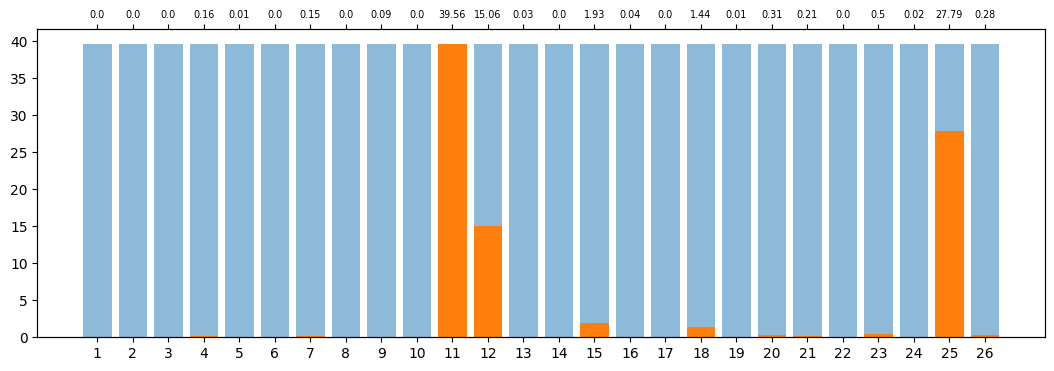

[0.0, 0.0, 0.0, 0.16, 0.01, 0.0, 0.15, 0.0, 0.09, 0.0, 39.56, 15.06, 0.03, 0.0, 1.93, 0.04, 0.0, 1.44, 0.01, 0.31, 0.21, 0.0, 0.5, 0.02, 27.79, 0.28]


In [17]:

tot_perc_list = show_blast_distribution_perc(ALL_DATASETS, return_perc = True)
print(tot_perc_list)

In [18]:

# splits patients in categoties
healthy_donors, blast_donors, mixed_donors = donor_division(multiple_donations, ALL_DATASETS)

# split patients indices in train, val and test
train_donors_idx, val_donors_idx, test_donors_idx = dataset_elaboration(multiple_donations, ALL_DATASETS, healthy_donors, blast_donors,
                        mixed_donors, seed = starting_seed)

print(train_donors_idx, val_donors_idx, test_donors_idx)

# extract files from patients indices
train_datasets_extracted = donation_extraction(train_donors_idx, multiple_donations, ALL_DATASETS)
val_datasets_extracted = donation_extraction(val_donors_idx, multiple_donations, ALL_DATASETS)
test_datasets_extracted = donation_extraction(test_donors_idx, multiple_donations, ALL_DATASETS)


{'11': [1, 1, 0], '12': [1, 1], '1': [1, 0], '2': [1, 1], '3': [1, 0], '4': [1, 1, 0], '6': [1, 1], '7': [1, 1, 0], '8': [1, 1], '9': [1, 1], '13': [0], '14': [0], '15': [0]}
Precess starts. Dividing donors...
healthy_donors_idx, blast_donors_idx, mixed_donors_idx: [0, 2, 1], [0, 4, 2, 1, 3],[4, 0, 2, 1, 3]
Seting Train, Validation and Test idx...
['12', '9', '13', '7'] ['6', '15', '3'] ['2', '8', '14', '11', '1', '4']
['12', '9', '13', '7'] ['6', '15', '3'] ['2', '8', '14', '11', '1', '4']


In [19]:

external_test_donors_idx = test_donors_idx
print(external_test_donors_idx)


['2', '8', '14', '11', '1', '4']


# prepare stratified CV and  parameter tuning + classical kfold cv

In [20]:
h_pat, b_pat, m_pat, tot_pat = remove_test_patients_from_categories(healthy_donors, blast_donors, mixed_donors, external_test_donors_idx)

strat_folds = strat_CV(h_pat, b_pat, m_pat, shuffle = True, seed = None)

print(strat_folds)

fold_features = extract_fold_features(strat_folds)

Remaining Patients: healthy = ['13', '15'], unhealthy = ['12', '6', '9'], mixed = ['3', '7']
All Patients in Train + Validation set: ['13', '12', '3', '15', '6', '7', '9']
['13', '15'] ['12', '6', '9'] ['3', '7']
['13', '15'] ['6', '9', '12'] ['7', '3']
[[['15', '9', '3', '12'], ['13', '6', '7']], [['13', '6', '7', '12'], ['15', '9', '3']], [['13', '6', '7', '15', '9', '3'], ['12']]]


In [21]:

blocks = 20
nsub_step = 50
max_ncells = 1000
ncells_step = 100

config['blocks'] = blocks
config['nsub_step'] = nsub_step
config['max_ncells'] = max_ncells
config['ncells_step'] = ncells_step

config_save_dir = f'{cellcnn_path}/New running ipynb/Fixed/5.LOOCV_final_run/Ensamble/folds_results/experiment_{exp}/'
os.makedirs(config_save_dir, exist_ok=True)

with open(os.path.join(config_save_dir, 'config.pkl'), 'wb') as f:
            pickle.dump(config, f)

ncells_list = list(range(ncells_step, max_ncells + ncells_step, ncells_step))
nsub_list = list(range(nsub_step, blocks*nsub_step + nsub_step, nsub_step))
print(ncells_list)
print(nsub_list)

# all possible combinations of parameters
def nsub_ncells_comb(ncells_list, nsub_list):
    all_nsub_ncells_comb = []
    for ncells_value in ncells_list:
        for nsub_value in nsub_list:
            all_nsub_ncells_comb.append([ncells_value, nsub_value])
    return all_nsub_ncells_comb

all_nsub_ncells_comb = nsub_ncells_comb(ncells_list, nsub_list)

[100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]
[50, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 600, 650, 700, 750, 800, 850, 900, 950, 1000]


In [22]:
h_pat, b_pat, m_pat, tot_pat = remove_test_patients_from_categories(healthy_donors, blast_donors, mixed_donors, external_test_donors_idx)

k_folds = classic_CV_train_val_splits(h_pat, b_pat, m_pat, tot_pat, folds = 5, LOOCV_test = None)

Remaining Patients: healthy = ['13', '15'], unhealthy = ['12', '6', '9'], mixed = ['3', '7']
All Patients in Train + Validation set: ['13', '12', '3', '15', '6', '7', '9']
Minimum number of patients in each fold: 1
Folds: [['13'], ['12'], ['3', '15'], ['6'], ['7', '9']]
Combination 1: (['13', '12', '3', '15', '6'], ['7', '9'])
Combination 2: (['12', '3', '15', '6', '7', '9'], ['13'])
Combination 3: (['13', '3', '15', '6', '7', '9'], ['12'])
Combination 4: (['13', '12', '6', '7', '9'], ['3', '15'])
Combination 5: (['13', '12', '3', '15', '7', '9'], ['6'])


In [23]:
resampling_seeds = generate_seeds(len(k_folds)*2, seed = starting_seed)
print(resampling_seeds)


[815173 413213 477711 914485 426440 593669 743992  19575 195005 867690]


# Pre build of Artificial sample to avoid reload files

In [24]:
import optuna
import time
import numpy as np
    ####################################################
    ##### 3-Fold stratified CV
    ####################################################

counter_resampling_seed = 0 ###
    
    #Fold feature dictionaty creation 
strat_fold_features = extract_fold_features(strat_folds)
    
    ####################################################
    ##### Tuning section: nsub and ncell 
    ####################################################
artificial_samples_folds = []
for fold, (train_features, val_features) in strat_fold_features.items():
    train_donors_idx, val_donors_idx = train_features[0], val_features[0] # retrieve patients form fold features dictionary
                    

    train_datasets_extracted = donation_extraction(train_donors_idx, multiple_donations, ALL_DATASETS) 
    val_datasets_extracted = donation_extraction(val_donors_idx, multiple_donations, ALL_DATASETS)
    test_datasets_extracted = donation_extraction(test_donors_idx, multiple_donations, ALL_DATASETS)
 
                
                ##### Artificial generation of Datasets used to train the model #####
    
    #seed = 105619
    n_cells = 100000  
    blast_perc = blast_perc
    n_sub = len(blast_perc) ### 3
                # generate Artificial Samples
    new_train_datasets, new_train_y, new_val_datasets, new_val_y, new_test_datasets, new_test_y = splitting_and_dataset_elaboration(train_datasets_extracted, 
                                                                                                    val_datasets_extracted, test_datasets_extracted,
                                                                                                    n_sub, n_cells, starting_seed, blast_perc = blast_perc, per_perc = True)
            
            
    artificial_samples_folds.append([new_train_datasets, new_train_y, new_val_datasets, new_val_y, new_test_datasets, new_test_y])
    
del ALL_DATASETS
del test_datasets_extracted   
del train_datasets_extracted  
del new_test_datasets         
del new_train_datasets                             
del val_datasets_extracted  
del new_val_datasets          
    

New training datasets creation...
4
1

New Donor
1
Timepoint condition: Healthy
Extraction Done
Condition: 0

New Donor
2
Tot blast data in the donor timepoints: 44697
Tot blast data in the donor timepoints: 46110
Extraction Done
Condition: 1
3
0
1
[0.0001, 0.001, 0.01]
3
Chosen # of blast cells: [  10.  100. 1000.]
Chosen # of blast cells: [  10.  100. 1000.]

New Donor
2
Tot blast data in the donor timepoints: 72
Tot blast data in the donor timepoints: 72
Extraction Done
Condition: 1
3
0
1
[0.0001, 0.001, 0.01]
3
Chosen # of blast cells: [  10.  100. 1000.]
Chosen # of blast cells: [  10.  100. 1000.]

New Donor
2
Tot blast data in the donor timepoints: 639
Tot blast data in the donor timepoints: 654
Extraction Done
Condition: 1
3
0
1
[0.0001, 0.001, 0.01]
3
Chosen # of blast cells: [  10.  100. 1000.]
Chosen # of blast cells: [  10.  100. 1000.]
[0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0]
Done!

New training datasets creation...

New Donor
Timepoint condition: He

In [25]:
print_var_memory()

Variable                  Type                          Memory
-----------------------------------------------------------------
artificial_samples_folds  list                       947.60 MB
-----------------------------------------------------------------
TOTAL                                                  0.93 GB


['artificial_samples_folds']

# ncells and nsub bayesian tuning

In [26]:
%%time
#baywsian search and ncells and nsub tuning
resampling_seeds = generate_seeds(len(k_folds)*2, seed = starting_seed)
print(resampling_seeds)

for i in range(1):
    hyper = (nfilter, maxpool_p, learning_r)
    grid = False
    labels = False
    

    bayesian_mean_f1 = []
    bayesian_f1 = []
    bayesian_acc = []
    tested_par = []
                ##### Run ncells tuning #####
            # 1. Crea lo studio fuori dal loop.
            # direction="maximize" perché vogliamo massimizzare l'F1 score.
    study = optuna.create_study(direction="maximize")
            
            # Definisci qui la tua lista di combinazioni se vuoi pescare da lì
    all_nsub_ncells_comb = nsub_ncells_comb(ncells_list, nsub_list)
            
    print(f"Inizio ottimizzazione Bayesiana su {len(all_nsub_ncells_comb)} combinazioni possibili...")
            
    bayesian_comb = 20 ### 20
    for i in range(bayesian_comb):
        
        
        # --- STEP 1: ASK (Chiedi i parametri) ---
        trial = study.ask()
                
        # Ottimizziamo l'indice della lista.
        comb_index = trial.suggest_int("combo_idx", 0, len(all_nsub_ncells_comb) - 1)
        n_cells, nsubs = all_nsub_ncells_comb[comb_index]
        tested_par.append((n_cells, nsubs))

        ncell_start = time.time()
        print(f'Model {i+1}. Testing params -> n_cells: {n_cells}, nsubs: {nsubs}')
                
        for fold, (train_features, val_features) in strat_fold_features.items():
            
            print(f'\nFold: {fold}\n')
            start = time.time()
            new_train_datasets, new_train_y, new_val_datasets, new_val_y, new_test_datasets, new_test_y = artificial_samples_folds[fold]
            
            seed_list = generate_seeds(len(strat_fold_features)*2, seed = starting_seed + fold)
            
            ##### Prepare Parameters and storage variables #####
            CellCnn = grid_or_rand_model(grid) #select the correct model
    
            # remove labels (random search without labels is required)
            train, val = train_val_finalizing(new_train_datasets, new_val_datasets, grid, labels) 
            test = None
            trials = 1 ### 3 
        
            counter = 0
            max_acc = 0
            max_f1 = 0
            
            ncell_acc, ncell_f1 = [], []
            f1_ncells_5_to_plot = []
        

                # Preparazione seed (dal tuo codice)
            seed = seed_list[counter + 3:] 
            
                # --- STEP 2: TRAINING (Il tuo codice esistente) ---
            try:
                    # Train
                    models_lists = trials_train_CellCNN_old(
                        CellCnn, train, new_train_y, 
                        val_datasets=val, val_y=new_val_y, test_datasets_no_labels=test, 
                        trials=trials, 
                        n_cell=n_cells,   # Parametro suggerito dall'algoritmo
                        nsubset=nsubs,    # Parametro suggerito dall'algoritmo
                        max_epochs=35,     ### 35
                        nrun=10,           ### 10
                        seed_list=seed, hyper=hyper
                    )
            
                    # Predicts
                    predictions_list, results_list = trials_test_CellCNN_old(models_lists, val)
            
                    # Extract results
                    pred_phenotype_df, accuracy_list, f1_scores_list = elaborate_predictions(
                        predictions_list, new_val_y, results=True
                    )
            
                    mean_ncells_f1 = np.mean(f1_scores_list)
                    
                    # Codice tuo per plotting/storage
                    f1_ncells_5_to_plot.append(mean_ncells_f1)
                    ncell_acc.append(accuracy_list)
                    ncell_f1.append(f1_scores_list)
                    
            except Exception as e:
                    # È buona pratica gestire errori nel training per non bloccare l'ottimizzazione
                    print(f"Errore nel training: {e}")
                    mean_ncells_f1 = 0.0 # Penalizza il fallimento


            counter += 1
            ncell_end = time.time()
                
                # --- STEP 3: TELL (Informa l'algoritmo del risultato) ---
                # Questo è fondamentale: aggiorna la distribuzione di probabilità Bayesiana per la prossima iterazione.
        study.tell(trial, mean_ncells_f1)
                
        print(f'F1 Score ottenuto: {mean_ncells_f1}')
        print(f'Time Spent for this trial: {ncell_end - ncell_start}')
        
        bayesian_mean_f1.append(f1_ncells_5_to_plot)
        bayesian_f1.append(ncell_f1)
        bayesian_acc.append(ncell_acc)

    
    # Risultato finale
    print("Migliori parametri trovati:")
    print(study.best_params)
    
best_ncells, best_nsub = all_nsub_ncells_comb[study.best_params['combo_idx']]

tuning_save_dir = f'{cellcnn_path}/New running ipynb/Fixed/5.LOOCV_final_run/Ensamble/folds_results/experiment_{exp}/strat-fold/'
os.makedirs(tuning_save_dir, exist_ok=True)

with open(os.path.join(tuning_save_dir, 'bayesian_mean_f1.pkl'), 'wb') as f:
            pickle.dump(bayesian_mean_f1, f)
with open(os.path.join(tuning_save_dir, 'bayesian_f1.pkl'), 'wb') as f:
            pickle.dump(bayesian_f1, f)
with open(os.path.join(tuning_save_dir, 'bayesian_acc.pkl'), 'wb') as f:
            pickle.dump(bayesian_acc, f)
with open(os.path.join(tuning_save_dir, 'best_ncells.pkl'), 'wb') as f:
            pickle.dump(best_ncells, f)
with open(os.path.join(tuning_save_dir, 'best_nsub.pkl'), 'wb') as f:
            pickle.dump(best_nsub, f)
with open(os.path.join(tuning_save_dir, 'tested_par.pkl'), 'wb') as f:
            pickle.dump(tested_par, f)
    

[I 2026-01-07 01:59:41,655] A new study created in memory with name: no-name-9064bb06-ba18-43a0-951e-c99029bd1c62


[815173 413213 477711 914485 426440 593669 743992  19575 195005 867690]
Inizio ottimizzazione Bayesiana su 200 combinazioni possibili...
Model 1. Testing params -> n_cells: 100, nsubs: 300

Fold: 0

old_cellCnn.model rimosso dalla cache
21
15
labels from Train and Validations Sets have been REMOVED.
Random Search Ready!
Trial 1 started
Seed used: 914485
Model defined...
Fitting started...
No labels detected. Labels set to False
[0 0 0 1 1 1 0 0 0 1 1 1 0 0 0 1 1 1 0 0 0]
11
11

# ============================================= #
Run: 0

Seed: 914485

 filters: 5


 filters: 5

Epoch 1/35
32/32 [==============================] - 12s 132ms/step - loss: 0.6843 - f1_score: 0.3844 - val_loss: 0.6727 - val_f1_score: 0.3750
Epoch 2/35
32/32 [==============================] - 0s 5ms/step - loss: 0.6759 - f1_score: 0.4940 - val_loss: 0.6676 - val_f1_score: 0.4358
Epoch 3/35
32/32 [==============================] - 0s 5ms/step - loss: 0.6668 - f1_score: 0.5331 - val_loss: 0.6618 - val_f1_score: 0.

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

1
Prediction started...

 filters: 9



C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

1/1 [==============================] - 0s 373ms/step

 filters: 7

1/1 [==============================] - 0s 118ms/step

 filters: 5

1/1 [==============================] - 0s 111ms/step
Done
Trial 1 Done!

Trial 0 Accuracy: 0.6
Trial 0 F1_score: 0.6666666666666666
Trial 0 F1_score: 1.0
             0   1   2   3   4   5   6   7   8   9   10  11  12  13  14
0             0   0   0   1   1   1   1   1   1   1   1   1   1   1   1
True Labels   0   0   0   1   1   1   0   0   0   1   1   1   0   0   0
mean_accuracy over the ten trials: 0.6
accuracy_std over the ten trials: 0.0
mean_f1 over the ten trials: 0.6666666666666666
std_f1 over the ten trials: 0.0
mean_recall over the ten trials: 1.0
std_recall over the ten trials: 0.0
Errore nel training: too many values to unpack (expected 3)

Fold: 1

old_cellCnn.model rimosso dalla cache
21
15
labels from Train and Validations Sets have been REMOVED.
Random Search Ready!
Trial 1 started
Seed used: 258616
Model defined...
Fitting started...
No 

... (220 outputs left out)

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

1
Prediction started...

 filters: 9



C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

1/1 [==============================] - 0s 112ms/step

 filters: 5

1/1 [==============================] - 0s 85ms/step

 filters: 9

1/1 [==============================] - 0s 177ms/step
Done
Trial 1 Done!

Trial 0 Accuracy: 0.5
Trial 0 F1_score: 0.0
Trial 0 F1_score: 0.0
             0  1  2  3  4  5
0            0  0  0  0  0  0
True Labels  1  1  1  0  0  0
mean_accuracy over the ten trials: 0.5
accuracy_std over the ten trials: 0.0
mean_f1 over the ten trials: 0.0
std_f1 over the ten trials: 0.0
mean_recall over the ten trials: 0.0
std_recall over the ten trials: 0.0
Errore nel training: too many values to unpack (expected 3)
F1 Score ottenuto: 0.0
Time Spent for this trial: 280.3227503299713
Migliori parametri trovati:
{'combo_idx': 5}
CPU times: total: 21h 1min 11s
Wall time: 10h 58min 29s


In [27]:
print(best_ncells, best_nsub)

100 300


In [22]:
%%time

# Trova tutti i file con estensione specifica in una cartella
data_folder = f'{fixed_path}B-ALL_Datasets'
extension = '*.csv'  # cambia con l'estensione che ti serve

multiple_donations, ALL_DATASETS = load_data(data_path = data_folder, ext = extension)

# splits patients in categoties
healthy_donors, blast_donors, mixed_donors = donor_division(multiple_donations, ALL_DATASETS)

# split patients indices in train, val and test
train_donors_idx, val_donors_idx, test_donors_idx = dataset_elaboration(multiple_donations, ALL_DATASETS, healthy_donors, blast_donors,
                        mixed_donors, seed = starting_seed)

print(train_donors_idx, val_donors_idx, test_donors_idx)

# extract files from patients indices
train_datasets_extracted = donation_extraction(train_donors_idx, multiple_donations, ALL_DATASETS)
val_datasets_extracted = donation_extraction(val_donors_idx, multiple_donations, ALL_DATASETS)
test_datasets_extracted = donation_extraction(test_donors_idx, multiple_donations, ALL_DATASETS)

external_test_donors_idx = test_donors_idx
print(external_test_donors_idx)


Elaborating file 0: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_220204-2900.csv
Elaborating file 1: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_220208-3665.csv
Elaborating file 2: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_220216-3546.csv
Elaborating file 3: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D15_1.csv
Elaborating file 4: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D29_1.csv
Elaborating file 5: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D71_1.csv
Elaborating file 6: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE12_D15_2.csv
Elaborating file 7: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE12_D29_1.csv
Elaborating file 8: C:\Users\Enrico Didoli\0.Master_Thesis

In [43]:
#best ncells and nsub

print(all_nsub_ncells_comb[study.best_params['combo_idx']])
best_ncells, best_nsub = all_nsub_ncells_comb[study.best_params['combo_idx']]
print(best_ncells, best_nsub)



[700, 750]
700 750
700 1000


In [129]:
%%time
# pre generate Artificial samples

import optuna
import time
import numpy as np
    ####################################################
    ##### 3-Fold stratified CV
    ####################################################

counter_resampling_seed = 0 ###
    
    #Fold feature dictionaty creation 
k_fold_features = extract_fold_features(k_folds)
    
    ####################################################
    ##### Tuning section: nsub and ncell 
    ####################################################
artificial_samples_folds = []
for fold, (train_features, val_features) in k_fold_features.items():

    train_donors_idx, val_donors_idx = train_features[0], val_features[0] # retrieve patients form fold features dictionary
                    
                # import data (done every time to save memory)
                ### multiple_donations, ALL_DATASETS = load_data(data_path = data_folder, ext = extension) # load data
    train_datasets_extracted = donation_extraction(train_donors_idx, multiple_donations, ALL_DATASETS) 
    val_datasets_extracted = donation_extraction(val_donors_idx, multiple_donations, ALL_DATASETS)
    test_datasets_extracted = donation_extraction(test_donors_idx, multiple_donations, ALL_DATASETS)
                ### del ALL_DATASETS
                
                ##### Artificial generation of Datasets used to train the model #####
    n_sub = 3
    #seed = 105619
    n_cells = 100000  
    blast_perc = blast_perc
        
                # generate Artificial Samples
    new_train_datasets, new_train_y, new_val_datasets, new_val_y, new_test_datasets, new_test_y = splitting_and_dataset_elaboration(train_datasets_extracted, 
                                                                                                    val_datasets_extracted, test_datasets_extracted,
                                                                                                    n_sub, n_cells, starting_seed, blast_perc = blast_perc, per_perc = True)
            
            
    artificial_samples_folds.append([new_train_datasets, new_train_y, new_val_datasets, new_val_y, new_test_datasets, new_test_y])

del ALL_DATASETS
del test_datasets_extracted   
del train_datasets_extracted  
del new_test_datasets         
del new_train_datasets                           
del val_datasets_extracted  
del new_val_datasets          


New training datasets creation...
5
1

New Donor
1
Timepoint condition: Healthy
Extraction Done
Condition: 0

New Donor
2
Tot blast data in the donor timepoints: 639
Tot blast data in the donor timepoints: 654
Extraction Done
Condition: 1
3
0
1
[0.0001, 0.001, 0.01]
3
Chosen # of blast cells: [  10.  100. 1000.]
Chosen # of blast cells: [  10.  100. 1000.]

New Donor
2
Tot blast data in the donor timepoints: 72
Tot blast data in the donor timepoints: 72
Extraction Done
Condition: 1
3
0
1
[0.0001, 0.001, 0.01]
3
Chosen # of blast cells: [  10.  100. 1000.]
Chosen # of blast cells: [  10.  100. 1000.]

New Donor
1
Timepoint condition: Healthy
Extraction Done
Condition: 0

New Donor
2
Tot blast data in the donor timepoints: 9147
Tot blast data in the donor timepoints: 9374
Extraction Done
Condition: 1
3
0
1
[0.0001, 0.001, 0.01]
3
Chosen # of blast cells: [  10.  100. 1000.]
Chosen # of blast cells: [  10.  100. 1000.]
[0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 

In [77]:
print_var_memory()

Variable                  Type                          Memory
-----------------------------------------------------------------
artificial_samples_folds  list                         1.54 GB
external_test_datasets_extracted list                         1.13 GB
per_donor_original_test_datasets list                         1.13 GB
donor                     list                       313.98 MB
-----------------------------------------------------------------
TOTAL                                                  4.10 GB


['artificial_samples_folds',
 'external_test_datasets_extracted',
 'per_donor_original_test_datasets',
 'donor']

# Run k fold CV

In [46]:
%%time
#model training for fold in the classicla k fold CV

for fold, (train_features, val_features) in k_fold_features.items():
            
                print(f'\nFold: {fold}\n')
                start = time.time()
                new_train_datasets, new_train_y, new_val_datasets, new_val_y, new_test_datasets, new_test_y = artificial_samples_folds[fold]
            
                ##### FUNCTION MODIFIeD TO BE ALWAYS WITHOUT VALIDATION SET #####
                seed_list = generate_seeds(len(k_fold_features)*2, seed = starting_seed + len(strat_fold_features) + fold)
                trials = 5 ### 1
                best_ncells = best_ncells
                best_nsub =  best_nsub
                print(f'Tuned ncells value: {best_ncells}')
                print(f'Tuned nsub value: {best_nsub}')
                
                grid = True  #grid search
                labels = False # the  subsets sampled by the model do not maintain original blast distribution
                CellCnn = grid_or_rand_model(grid) # loads the correct model module
                
                # no early stopping
                models_lists = run_training(CellCnn, new_train_datasets, new_train_y,
                                            new_val_datasets = new_val_datasets, new_val_y = new_val_y, 
                                            new_test_datasets = None, 
                                            seed_list =  seed_list, hyper = hyper, grid = grid, labels = labels,
                                            trials = trials,
                                            cells_per_sub =  best_ncells, ### Tuned ncells ###
                                            best_nsub = best_nsub,  ### Tuned nsub   ###
                                            max_epochs = 100, ### 100,
                                            nrun = 3, #grid search, so doesn't matter wht number 
                                            generate = False, no_val = False)


                # 1. Definisci il nome della cartella dove salvare tutto (per ordine)
                for i, model in enumerate(models_lists):
                    save_dir = f'{cellcnn_path}/New running ipynb/Fixed/5.LOOCV_final_run/Ensamble/folds_results/experiment_{exp}/k-fold/Fold_{fold}/model_{i}'
                    os.makedirs(save_dir, exist_ok=True)
                    save_models(model, save_dir)

                    build_model_parms = {}
                    build_model_parms['ncells'] = best_ncells
                    build_model_parms['nsubset'] = best_nsub
                    build_model_parms['per_sample'] = True
                    build_model_parms['nfilter_choice'] = nfilter
                    build_model_parms['maxpool_percentages'] = maxpool_p
                    build_model_parms['learning_rate'] = learning_r
                    build_model_parms['max_epochs'] = 5
                    build_model_parms['patience'] = 5
                    build_model_parms['nrun'] = 5
                    build_model_parms['regression'] = False
                    build_model_parms['scale'] = True
                    build_model_parms['verbose'] = 1
                    build_model_parms['seed'] = seed
                    
                    with open(os.path.join(save_dir, 'model_params.pkl'), 'wb') as f:
                        pickle.dump(build_model_parms, f)
                        print(f"✅ build_model_parms salvati in {save_dir}/model_params.pkl")




Fold: 0

Tuned ncells value: 700
Tuned nsub value: 1000
old_cellCnn.model_grid rimosso dalla cache
24
12
_abels from Train and Validations Sets have been REMOVED.
Grid Search Ready!
0
Trial 1 started
Seed used: 395093
Model defined...
Fitting started...
[0 0 0 1 1 1 0 0 0 1 1 1 0 0 0 0 0 0 1 1 1 0 0 0]
(3, 0.01, 0.001)
(3, 1.0, 0.001)
(3, 5.0, 0.001)
(3, 20.0, 0.001)
(3, 100.0, 0.001)
(5, 0.01, 0.001)
(5, 1.0, 0.001)
(5, 5.0, 0.001)
(5, 20.0, 0.001)
(5, 100.0, 0.001)
(7, 0.01, 0.001)
(7, 1.0, 0.001)
(7, 5.0, 0.001)
(7, 20.0, 0.001)
(7, 100.0, 0.001)
(9, 0.01, 0.001)
(9, 1.0, 0.001)
(9, 5.0, 0.001)
(9, 20.0, 0.001)
(9, 100.0, 0.001)
Total number of selections: 20

# ============================================= #
Run: 0

Seed: 395093
Adopted Parameters: (3, 0.01, 0.001)
False
Epoch 1/100
120/120 [==============================] - 4s 23ms/step - loss: 0.6740 - f1_score: 0.4007 - val_loss: 0.7136 - val_f1_score: 0.3333
Epoch 2/100
120/120 [==============================] - 2s 14ms/step -

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

Trial 2 started
Seed used: 419212
Model defined...
Fitting started...
[0 0 0 1 1 1 0 0 0 1 1 1 0 0 0 0 0 0 1 1 1 0 0 0]
(3, 0.01, 0.001)
(3, 1.0, 0.001)
(3, 5.0, 0.001)
(3, 20.0, 0.001)
(3, 100.0, 0.001)
(5, 0.01, 0.001)
(5, 1.0, 0.001)
(5, 5.0, 0.001)
(5, 20.0, 0.001)
(5, 100.0, 0.001)
(7, 0.01, 0.001)
(7, 1.0, 0.001)
(7, 5.0, 0.001)
(7, 20.0, 0.001)
(7, 100.0, 0.001)
(9, 0.01, 0.001)
(9, 1.0, 0.001)
(9, 5.0, 0.001)
(9, 20.0, 0.001)
(9, 100.0, 0.001)
Total number of selections: 20

# ============================================= #
Run: 0

Seed: 419212
Adopted Parameters: (3, 0.01, 0.001)
False
Epoch 1/100
120/120 [==============================] - 3s 23ms/step - loss: 0.6739 - f1_score: 0.4018 - val_loss: 0.7131 - val_f1_score: 0.3333
Epoch 2/100
120/120 [==============================] - 2s 15ms/step - loss: 0.6619 - f1_score: 0.3846 - val_loss: 0.7143 - val_f1_score: 0.3333
Epoch 3/100
120/120 [==============================] - 2s 16ms/step - loss: 0.6589 - f1_score: 0.3846 - val_lo

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

Trial 3 started
Seed used: 557754
Model defined...
Fitting started...
[0 0 0 1 1 1 0 0 0 1 1 1 0 0 0 0 0 0 1 1 1 0 0 0]
(3, 0.01, 0.001)
(3, 1.0, 0.001)
(3, 5.0, 0.001)
(3, 20.0, 0.001)
(3, 100.0, 0.001)
(5, 0.01, 0.001)
(5, 1.0, 0.001)
(5, 5.0, 0.001)
(5, 20.0, 0.001)
(5, 100.0, 0.001)
(7, 0.01, 0.001)
(7, 1.0, 0.001)
(7, 5.0, 0.001)
(7, 20.0, 0.001)
(7, 100.0, 0.001)
(9, 0.01, 0.001)
(9, 1.0, 0.001)
(9, 5.0, 0.001)
(9, 20.0, 0.001)
(9, 100.0, 0.001)
Total number of selections: 20

# ============================================= #
Run: 0

Seed: 557754
Adopted Parameters: (3, 0.01, 0.001)
False
Epoch 1/100
120/120 [==============================] - 5s 28ms/step - loss: 0.6739 - f1_score: 0.4019 - val_loss: 0.7133 - val_f1_score: 0.3333
Epoch 2/100
120/120 [==============================] - 2s 17ms/step - loss: 0.6621 - f1_score: 0.3846 - val_loss: 0.7164 - val_f1_score: 0.3333
Epoch 3/100
120/120 [==============================] - 2s 18ms/step - loss: 0.6603 - f1_score: 0.3846 - val_lo

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

... (41 outputs left out)

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

Trial 5 started
Seed used: 2038780
Model defined...
Fitting started...
[0 0 0 1 1 1 0 0 0 1 1 1 0 0 0 0 0 0 1 1 1 0 0 0 1 1 1 0 0 0]
(3, 0.01, 0.001)
(3, 1.0, 0.001)
(3, 5.0, 0.001)
(3, 20.0, 0.001)
(3, 100.0, 0.001)
(5, 0.01, 0.001)
(5, 1.0, 0.001)
(5, 5.0, 0.001)
(5, 20.0, 0.001)
(5, 100.0, 0.001)
(7, 0.01, 0.001)
(7, 1.0, 0.001)
(7, 5.0, 0.001)
(7, 20.0, 0.001)
(7, 100.0, 0.001)
(9, 0.01, 0.001)
(9, 1.0, 0.001)
(9, 5.0, 0.001)
(9, 20.0, 0.001)
(9, 100.0, 0.001)
Total number of selections: 20

# ============================================= #
Run: 0

Seed: 2038780
Adopted Parameters: (3, 0.01, 0.001)
False
Epoch 1/100
150/150 [==============================] - 4s 15ms/step - loss: 0.6795 - f1_score: 0.3888 - val_loss: 0.7111 - val_f1_score: 0.3333
Epoch 2/100
150/150 [==============================] - 2s 12ms/step - loss: 0.6730 - f1_score: 0.3750 - val_loss: 0.7119 - val_f1_score: 0.3333
Epoch 3/100
150/150 [==============================] - 2s 12ms/step - loss: 0.6704 - f1_score: 0

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

✅ Metadata salvati in C:\Users\Enrico Didoli\0.Master_Thesis\CellCNN//New running ipynb/Fixed/5.LOOCV_final_run/Ensamble/folds_results/experiment_0/k-fold/Fold_4/model_0/metadata.pkl
✅ build_model_parms salvati in C:\Users\Enrico Didoli\0.Master_Thesis\CellCNN//New running ipynb/Fixed/5.LOOCV_final_run/Ensamble/folds_results/experiment_0/k-fold/Fold_4/model_0/model_params.pkl
✅ Metadata salvati in C:\Users\Enrico Didoli\0.Master_Thesis\CellCNN//New running ipynb/Fixed/5.LOOCV_final_run/Ensamble/folds_results/experiment_0/k-fold/Fold_4/model_1/metadata.pkl
✅ build_model_parms salvati in C:\Users\Enrico Didoli\0.Master_Thesis\CellCNN//New running ipynb/Fixed/5.LOOCV_final_run/Ensamble/folds_results/experiment_0/k-fold/Fold_4/model_1/model_params.pkl
✅ Metadata salvati in C:\Users\Enrico Didoli\0.Master_Thesis\CellCNN//New running ipynb/Fixed/5.LOOCV_final_run/Ensamble/folds_results/experiment_0/k-fold/Fold_4/model_2/metadata.pkl
✅ build_model_parms salvati in C:\Users\Enrico Didoli\0.Mas

# Load and rebuild models  

In [55]:
print_var_memory()

Variable                  Type                          Memory
-----------------------------------------------------------------
ALL_DATASETS              list                         2.04 GB
external_test_datasets_extracted list                         1.13 GB
per_donor_original_test_datasets list                         1.13 GB
donor                     list                       313.98 MB
new_val_datasets          list                        27.47 MB
-----------------------------------------------------------------
TOTAL                                                  4.62 GB


['ALL_DATASETS',
 'external_test_datasets_extracted',
 'per_donor_original_test_datasets',
 'donor',
 'new_val_datasets']

In [130]:
exp = 2

In [122]:
%%time

# Trova tutti i file con estensione specifica in una cartella
data_folder = f'{fixed_path}B-ALL_Datasets'
extension = '*.csv'  # cambia con l'estensione che ti serve

multiple_donations, ALL_DATASETS = load_data(data_path = data_folder, ext = extension)


Elaborating file 0: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_220204-2900.csv
Elaborating file 1: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_220208-3665.csv
Elaborating file 2: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_220216-3546.csv
Elaborating file 3: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D15_1.csv
Elaborating file 4: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D29_1.csv
Elaborating file 5: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D71_1.csv
Elaborating file 6: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE12_D15_2.csv
Elaborating file 7: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE12_D29_1.csv
Elaborating file 8: C:\Users\Enrico Didoli\0.Master_Thesis

In [131]:
%%time
import pickle
import os
# Assicurati di avere la tua funzione per costruire il modello
# from tuo_file import build_cellcnn_model 

tot_original_predictions_list, tot_original_results_list = [], []
tot_mean_probs_per_patient = []
for fold, (train_features, val_features) in k_fold_features.items():
    print(f'\nFold: {fold}\n')
    start = time.time()
    train_donors_idx, val_donors_idx = train_features[0], val_features[0] # retrieve patients form fold features dictionary
                    
    val_datasets_extracted = donation_extraction(val_donors_idx, multiple_donations, ALL_DATASETS)
    new_train_datasets, new_train_y, new_val_datasets, new_val_y, new_test_datasets, new_test_y = artificial_samples_folds[fold]
    
    load_dir = f'{cellcnn_path}/New running ipynb/Fixed/5.LOOCV_final_run/Ensamble/folds_results/experiment_{exp}/k-fold/Fold_{fold}'
   
    all_trials = os.listdir(load_dir)
    print(f'all_trials: {all_trials}')

    loaded_models_lists = []
    for i, trial in enumerate(all_trials):
        print(trial)
        model_dir = f'{load_dir}/model_{i}'
        # A. Carica Config e Metadata
        with open(os.path.join(model_dir, 'metadata.pkl'), 'rb') as f:
            meta = pickle.load(f)
    
        # B. Carica i Pesi Grezzi
        with open(os.path.join(model_dir, 'model_params.pkl'), 'rb') as f:
            build_model_parms = pickle.load(f) # Questa è una lista di 3 liste di pesi

        ncells =            build_model_parms['ncells'] 
        best_nsub =            build_model_parms['nsubset'] 
        per_sample =           build_model_parms['per_sample'] 
        nfilter =           build_model_parms['nfilter_choice'] 
        maxpool_p =            build_model_parms['maxpool_percentages'] 
        learning_r =            build_model_parms['learning_rate'] 
        max_epochs = 5#build_model_parms['max_epochs']
        patience =            build_model_parms['patience'] 
        nrun =             build_model_parms['nrun'] 
        regression =            build_model_parms['regression'] 
        scale =            build_model_parms['scale']
        verbose =            build_model_parms['verbose'] 
        seed =            build_model_parms['seed'] 

        
        model = CellCnn(
            ncell = n_cells,                                   # Number of cells per nsubset (sampled from the 'patient' datasets)
            nsubset = best_nsub,                                    
            per_sample = per_sample,                                # For each sample, nsubset samples of ncell are created
            nfilter_choice = nfilter,                        # Range of possible number of filters
            maxpool_percentages = maxpool_p,    # list of k-percentage max_pooling
            learning_rate = learning_r,                               # Learning rate
            max_epochs = max_epochs,  #50
            patience=patience,                                       # Early stopping patience
            nrun = nrun,  #15                                 # Number of neural network configurations (for Hyperparameter optimization)
            regression=regression,
            scale=scale,                                       # Z-score normalization
            verbose=verbose,
            seed=seed
        )
        
        model.results = meta
        loaded_models_lists.append(model)
    #### LOAD MODELS AND WEIGHTS !!!!
    
                
                        # Prepare test dataset for the final prediction
    print(1)
    original_val_datasets, original_val_y = retrieve_labels(val_datasets_extracted, remove = True, flat = True)
                    
                    ####################################################
                    ##### Final Test
                    ####################################################
    print(2)
    original_predictions_list, original_results_list = trials_test_CellCNN_old(loaded_models_lists, original_val_datasets)

    # direct sampling
    if tot_original_predictions_list == []:
        for trial in original_predictions_list:
            tot_original_predictions_list.append(trial)
    else:
        for i, trial in enumerate(original_predictions_list):
            # here we want to concatenate because we want to obtain a dataframe containinf all files predictions for anty trial
            tot_original_predictions_list[i] = np.concatenate((tot_original_predictions_list[i], original_predictions_list[i]), axis = 0)

    per_donor_original_val_datasets, per_donor_original_val_y = retrieve_labels(val_datasets_extracted, remove = False) 


    
    # robust approach
    val_resample_n = 100000 #same dimension of the AS
    k = 50 ### 50
    seed = resampling_seeds[counter_resampling_seed]
    counter_resampling_seed += 1
    total_pred_lists, total_trial_pred_lists, mean_probs_per_patient = val_res_pred(loaded_models_lists, per_donor_original_val_datasets, val_resample_n, k, seed)

    # since mean_probs_per_patient sis a list of mean probs divided by patients, there is no need of concatenation
    for patient in mean_probs_per_patient:
        tot_mean_probs_per_patient.append(patient)
    #print(hfxc)
    ### threshold tuning ###
    best_threshold = 0
    
    """### Threshold ###"""
    best_threshold, tot_per_tr_f1_scores = find_robust_threshold(mean_probs_per_patient, 'f1')
    ### CHECK FOR FINAL THRESHOLD TUNING
    #print(Gbdfb)
 


Fold: 0



NameError: name 'ALL_DATASETS' is not defined

[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1.]
50
Chosen threshold: 50. Associated F1_score: 1.0


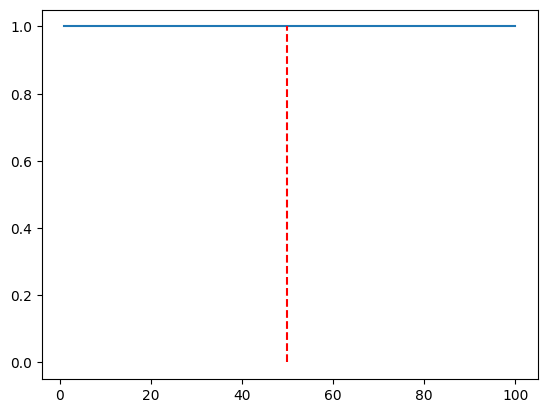

[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1.]
50
Chosen threshold: 50. Associated F1_score: 1.0


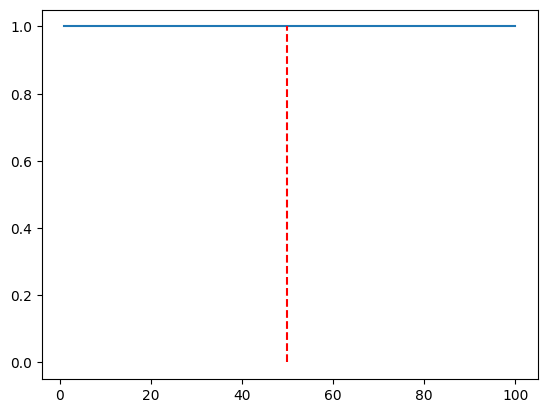

[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1.]
50
Chosen threshold: 50. Associated F1_score: 1.0


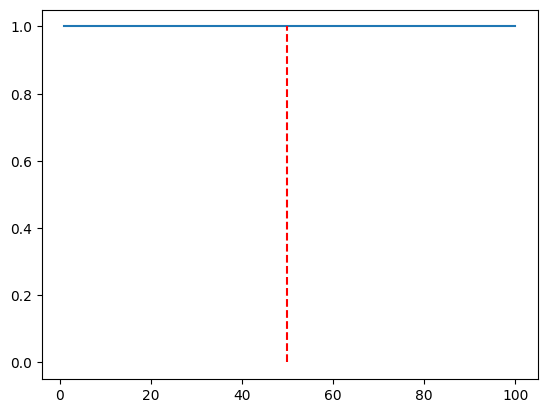

[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1.]
50
Chosen threshold: 50. Associated F1_score: 1.0


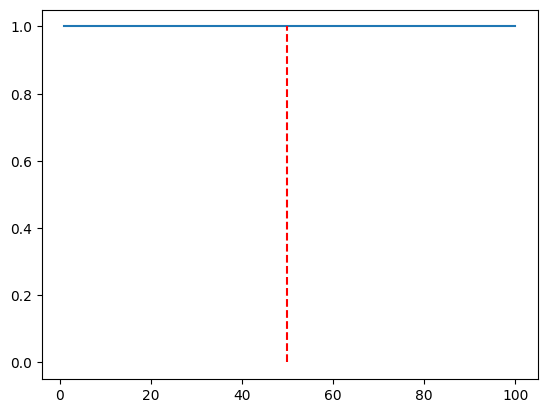

[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1.]
50
Chosen threshold: 50. Associated F1_score: 1.0


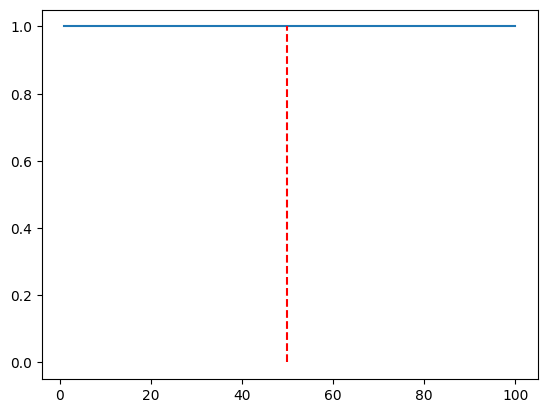

In [132]:
p = [1,1,2,1,2]
counter = 0
for p_i in p:
    fold = tot_mean_probs_per_patient[counter: counter + p_i]
    counter +=p_i
    best_threshold = 0
    
    """### Threshold ###"""
    best_threshold, tot_per_tr_f1_scores = find_robust_threshold(fold, 'f1', closest = True)
    ### CHECK FOR FINAL THRESHOLD TUNING
    #print(Gbdfb)
    plt.show()
 

In [133]:
for patient_probs_tuple in tot_mean_probs_per_patient:
            
    for timep, timep_res_y in patient_probs_tuple:
        #print(timep)
        #print(timep_res_y)
        #print('')
        print(np.mean(timep), 1 if np.mean(timep_res_y) > 0.5 else 0)
        #print('')

[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1.]
50
Chosen threshold: 50. Associated F1_score: 1.0


'#################'

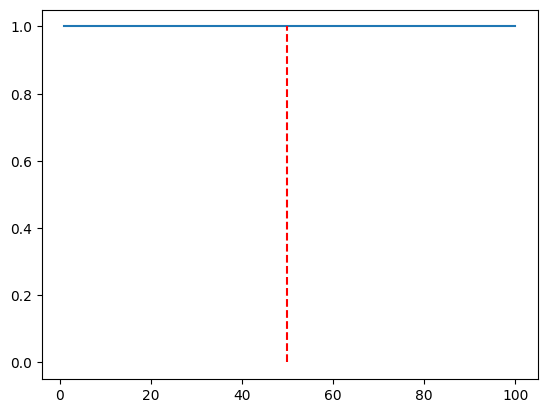

In [134]:
    ### threshold tuning ###
    best_threshold = 0
    
    """### Threshold ###"""
    best_threshold, tot_per_tr_f1_scores = find_robust_threshold(tot_mean_probs_per_patient, 'f1', closest = True)
    """#################"""

In [135]:
print_var_memory()


Variable                  Type                          Memory
-----------------------------------------------------------------
artificial_samples_folds  list                         1.54 GB
external_test_datasets_extracted list                         1.13 GB
per_donor_original_test_datasets list                         1.13 GB
donor                     list                       313.98 MB
-----------------------------------------------------------------
TOTAL                                                  4.10 GB


['artificial_samples_folds',
 'external_test_datasets_extracted',
 'per_donor_original_test_datasets',
 'donor']

In [136]:

del artificial_samples_folds
del per_donor_original_val_datasets
del val_datasets_extracted
del new_test_datasets
del original_val_datasets
del new_train_datasets
del train
del new_val_datasets
del val


NameError: name 'per_donor_original_val_datasets' is not defined

In [ ]:
%%time
predictions_for_fold = []

external_test_datasets_extracted = donation_extraction(external_test_donors_idx, multiple_donations, ALL_DATASETS)
per_donor_original_test_datasets, per_donor_original_test_y = retrieve_labels(external_test_datasets_extracted, remove = False)



for fold, _ in k_fold_features.items():

    load_dir = f'{cellcnn_path}/New running ipynb/Fixed/5.LOOCV_final_run/Ensamble/folds_results/experiment_{exp}/k-fold/Fold_{fold}'
   
    all_trials = os.listdir(load_dir)
    print(f'all_trials: {all_trials}')

    loaded_models_lists = []
    for i, trial in enumerate(all_trials):
        print(trial)
        model_dir = f'{load_dir}/model_{i}'
        # A. Carica Config e Metadata
        with open(os.path.join(model_dir, 'metadata.pkl'), 'rb') as f:
            meta = pickle.load(f)
    
        # B. Carica i Pesi Grezzi
        with open(os.path.join(model_dir, 'model_params.pkl'), 'rb') as f:
            build_model_parms = pickle.load(f) # Questa è una lista di 3 liste di pesi

        ncells =            build_model_parms['ncells'] 
        best_nsub =            build_model_parms['nsubset'] 
        per_sample =           build_model_parms['per_sample'] 
        nfilter =           build_model_parms['nfilter_choice'] 
        maxpool_p =            build_model_parms['maxpool_percentages'] 
        learning_r =            build_model_parms['learning_rate'] 
        max_epochs = 5          #build_model_parms['max_epochs']
        patience =            build_model_parms['patience'] 
        nrun =             build_model_parms['nrun'] 
        regression =            build_model_parms['regression'] 
        scale =            build_model_parms['scale']
        verbose =            build_model_parms['verbose'] 
        seed =            build_model_parms['seed'] 

        
        model = CellCnn(
            ncell = n_cells,                                   # Number of cells per nsubset (sampled from the 'patient' datasets)
            nsubset = best_nsub,                                    
            per_sample = per_sample,                                # For each sample, nsubset samples of ncell are created
            nfilter_choice = nfilter,                        # Range of possible number of filters
            maxpool_percentages = maxpool_p,    # list of k-percentage max_pooling
            learning_rate = learning_r,                               # Learning rate
            max_epochs = max_epochs,  #50
            patience=patience,                                       # Early stopping patience
            nrun = nrun,  #15                                 # Number of neural network configurations (for Hyperparameter optimization)
            regression=regression,
            scale=scale,                                       # Z-score normalization
            verbose=verbose,
            seed=seed
        )
        
        model.results = meta
        loaded_models_lists.append(model)
    
    # define subdivision to avoid stress RAM memory 
    sub_division = sub_resampling_list(k, nsub_per_sub = 30)
        
    # Extract test labels
    test_resample_n = 100000 #same dimension of AS
    k = 100 ### 100
    seed = 42#resampling_seeds[counter_resampling_seed]
    counter_resampling_seed += 1
    test_total_labels, test_total_pred_lists, test_total_trial_pred_lists, per_donor_resampled_test_y = test_res_pred(loaded_models_lists, per_donor_original_test_datasets, test_resample_n, k, seed, best_threshold, trials) 
    predictions_for_fold.append(test_total_pred_lists)

In [ ]:
test_total_labels # final labels
test_total_pred_lists # final predictions
#test_total_trial_pred_lists #
#per_donor_resampled_test_y
predictions_for_fold

import numpy as np

# Supponiamo che `all_cv_preds` sia una lista di K elementi (CV iterations)
# Ogni elemento: lista di N pazienti
# Ogni paziente: lista di F_i file
# Ogni file: array/lista di 2 valori

K = len(predictions_for_fold)
N = len(predictions_for_fold[0])  # numero di pazienti (assumiamo costante)

# Prepariamo una struttura per raccogliere le predizioni come array
# Usiamo una lista di liste per pazienti e file, poi convertiamo a numpy per mediare

# Raccogliamo tutti i valori per paziente e file
# patient_file_preds[p][f] = array di forma (K, 2)
final_patient_file_preds = []

for p in range(N):
    # Determina quanti file ha il paziente p (lo stesso in ogni CV iter)
    F = len(predictions_for_fold[0][p])
    file_preds = []
    for f in range(F):
        # Estrai le predizioni per questo (paziente p, file f) da tutte le CV iterations
        preds_across_cv = []
        for k in range(K):
            pred = predictions_for_fold[k][p][f]
            preds_across_cv.append(pred)
        # Converti in array (K, 2)
        preds_array = np.array(preds_across_cv)  # shape (K, 2)
        file_preds.append(preds_array.mean(axis=0))  # media su K → (2,)
    final_patient_file_preds.append(file_preds)

#print(patient_file_preds)
for patient, label in zip(final_patient_file_preds, per_donor_original_test_y):
    print(patient)
    print(label)
    print('')

total_trial_pred_lists = final_patient_file_preds

In [ ]:
from sklearn.metrics import f1_score

def final_trials_prediction(total_trial_pred_lists, per_donor_original_test_y, per_donor_resampled_test_y, best_threshold):
    from sklearn.metrics import f1_score
    """ Elaborate data to show distribution of trial results over the entire set of timepoints and patiets"""
    prob_data = []
    f1_data = []
    boxplot_data = []
    
    for patient, patient_ys, patient_resampled_y in zip(total_trial_pred_lists, per_donor_original_test_y, per_donor_resampled_test_y):

        for timepoint, true_timepoint_y, true_resampled_y in zip(patient, patient_ys, patient_resampled_y):
            label_str = "Positive" if true_timepoint_y == 1 else "Negative"
            
            timepoint_boxplot_data = []
            timepoint_f1_data = []
            #print(timepoint)
            for trial in timepoint: # from each timepoint multiple samples has been generated. each sample has been predicted 10 times using the same 'best' model but using a different seed each time
                             # each sub is a pediction of the 20 samples of a single timepoint

                #print(trial)
                trial_prob = np.mean(trial) # mean of the probabilities of the subsets
                
                trial_pred = (np.array(trial) >= best_threshold*0.01).astype(int)
                #print(trial_pred)
                #print(true_resampled_y)
                
                trial_f1 =  f1_score(true_resampled_y, trial_pred, pos_label = 1, zero_division=1)
                #print(rqver)
                
                prob_data.append({
                "True_Label": label_str,
                "Timepoint_Score": trial_prob
                })
                
                
                timepoint_boxplot_data.append(trial_prob)
                timepoint_f1_data.append(trial_f1)
                
            boxplot_data.append({
                "True_Label": true_timepoint_y,
                "Timepoint_trials_scores": timepoint_boxplot_data
                })
            
            f1_data.append({
                "True_Label": true_timepoint_y,
                "Timepoint_trials_scores": timepoint_f1_data
                })
                
    return prob_data, boxplot_data, f1_data
    
    
print(f'Predicted  Labels: {test_total_labels}')

print(f'Timepoints Labels: {per_donor_original_test_y}')

plot_data, boxplot_data, f1_data = final_trials_prediction(test_total_trial_pred_lists, 
                                                           per_donor_original_test_y, per_donor_resampled_test_y, best_threshold)
#print(plot_data)

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Convert your data into a DataFrame
df = pd.DataFrame(plot_data)

# --- Create the plot ---
plt.figure(figsize=(10, 6))

# A Violin plot is like a boxplot but shows the full distribution
sns.violinplot(
    x="True_Label", 
    y="Timepoint_Score", 
    data=df,
    order=["Negative", "Positive"] # Ensure this order
)

# You can also add a swarmplot to see the individual points
sns.swarmplot(
    x="True_Label",
    y="Timepoint_Score",
    data=df,
    color="black",
    alpha=0.2, # Make points transparent
    size=2,
    order=["Negative", "Positive"]
)

# --- Add your threshold line! ---
# This is the line that separates your predictions
TUNED_THRESHOLD = best_threshold # The threshold you found in your tuning
plt.axhline(y=TUNED_THRESHOLD*0.01, color='red', linestyle='--', label=f'Tuned Threshold ({TUNED_THRESHOLD})')
plt.ylim(-0.05, 1.05) # (Set the y-axis limit, 1.05 gives a little space)
plt.title('Timepoint Score Distribution vs. True Label (Across All Trials)')
plt.ylabel('Timepoint Blast Score')
plt.xlabel('True Timepoint Label')
plt.legend()
plt.show()


In [ ]:
print_var_memory()

In [ ]:
#print(boxplot_data)
timepoints_blast_perc = []
for donor in per_donor_original_test_datasets:
        for i, dataset in enumerate(donor):
            blast_n = (dataset['IsBlast'] == 1).sum()/len(dataset)
            timepoints_blast_perc.append(round(blast_n*100,4))
            
timepoints_labels = [timepoint["True_Label"] for i, timepoint in enumerate(boxplot_data)]
timepoints_trials_scores = [timepoint["Timepoint_trials_scores"] for timepoint in boxplot_data]
#print(timepoints_labels)
#print(timepoints_trials_scores)

# --- Your Solution (One Line) ---
# Create a figure and axes
fig, ax1 = plt.subplots(figsize=(10, 6))

# 2. Plot the boxplot on the first axes (ax1)
ax1.boxplot(timepoints_trials_scores, labels=timepoints_labels)
ax1.set_xlabel("Timepoint (Bottom)")
ax1.set_ylabel("Scores")

# 3. Create the SECOND axes (ax2)
ax2 = ax1.twiny()

# 4. Configure the second axes
# Make ax2 have the same limits and ticks as ax1
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(ax1.get_xticks()) # Positions [1, 2, 3, 4]

# Set the new labels for the top axis
ax2.set_xticklabels(timepoints_blast_perc)
ax2.set_xlabel("Group (Top)")
plt.axhline(y=TUNED_THRESHOLD*0.01, color='red', linestyle='--', label=f'Tuned Threshold ({TUNED_THRESHOLD})')

plt.title("Boxplots with Two X-Axes")
plt.show()

In [ ]:
print(time.time() - check_time_spent_start)